<a href="https://colab.research.google.com/github/maorufa/artemisinin-resistance-transcriptomics/blob/main/notebooks/GSE59097_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
!pip -q install GEOparse pandas numpy matplotlib seaborn

In [26]:
import GEOparse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [27]:
import os

folders = [
    "data/raw",
    "data/processed",
    "data/metadata",
    "results/figures",
    "results/tables"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [28]:
gse = GEOparse.get_GEO(
    "GSE59097",
    destdir="data/raw",
    how="brief"
)

print("Dataset downloaded successfully!")
print("Dataset ID:", gse.name)
print("Number of samples:", len(gse.gsms))
print("Number of platforms:", len(gse.gpls))

17-Nov-2026 06:16:04 DEBUG utils - Directory data/raw already exists. Skipping.
DEBUG:GEOparse:Directory data/raw already exists. Skipping.
17-Nov-2026 06:16:04 INFO GEOparse - File already exist: using local version.
INFO:GEOparse:File already exist: using local version.
17-Nov-2026 06:16:04 INFO GEOparse - Parsing data/raw/GSE59097.txt: 
INFO:GEOparse:Parsing data/raw/GSE59097.txt: 
17-Nov-2026 06:16:04 DEBUG GEOparse - SAMPLE: GSM1427365
DEBUG:GEOparse:SAMPLE: GSM1427365
17-Nov-2026 06:16:04 DEBUG GEOparse - SAMPLE: GSM1427366
DEBUG:GEOparse:SAMPLE: GSM1427366
17-Nov-2026 06:16:04 DEBUG GEOparse - SAMPLE: GSM1427367
DEBUG:GEOparse:SAMPLE: GSM1427367
17-Nov-2026 06:16:04 DEBUG GEOparse - SAMPLE: GSM1427368
DEBUG:GEOparse:SAMPLE: GSM1427368
17-Nov-2026 06:16:04 DEBUG GEOparse - SAMPLE: GSM1427369
DEBUG:GEOparse:SAMPLE: GSM1427369
17-Nov-2026 06:16:04 DEBUG GEOparse - SAMPLE: GSM1427370
DEBUG:GEOparse:SAMPLE: GSM1427370
17-Nov-2026 06:16:04 DEBUG GEOparse - SAMPLE: GSM1427371
DEBUG:GEO

Dataset downloaded successfully!
Dataset ID: None
Number of samples: 1043
Number of platforms: 0


In [29]:
print("First 5 sample IDs:")

for i, gsm_id in enumerate(gse.gsms.keys()):
    if i == 5:
        break
    print(gsm_id)

First 5 sample IDs:
GSM1427365
GSM1427366
GSM1427367
GSM1427368
GSM1427369


In [30]:
sample_id = list(gse.gsms.keys())[0]
sample = gse.gsms[sample_id]

print("Sample ID:", sample_id)
print("\nSample title:")
print(sample.metadata.get("title"))

print("\nCharacteristics:")
for item in sample.metadata.get("characteristics_ch1", []):
    print(item)

Sample ID: GSM1427365

Sample title:
['BD001-001-219888']

Characteristics:
culture: in vivo
Stage: blood
patient sample id: BD001-001
geographic origin: Ramu, Bangladesh
barcode: 219888
timepoint: prior to artemisinin combination therapy (ACT)
parasite clearance halflife upon artemisinin treatment (h): 4.142h


In [31]:
samples = []

for gsm_id, gsm in gse.gsms.items():

    sample_info = {
        "GSM_ID": gsm_id,
        "Title": gsm.metadata.get("title", [""])[0]
    }

    for item in gsm.metadata.get("characteristics_ch1", []):

        if ":" in item:
            key, value = item.split(":", 1)

            sample_info[key.strip()] = value.strip()

    samples.append(sample_info)

metadata = pd.DataFrame(samples)

print("Metadata table shape:", metadata.shape)

display(metadata.head(10))

Metadata table shape: (1043, 9)


,GSM_ID,Title,culture,Stage,patient sample id,geographic origin,barcode,timepoint,parasite clearance halflife upon artemisinin treatment (h)
0,GSM1427365,BD001-001-219888,in vivo,blood,BD001-001,"Ramu, Bangladesh",219888,prior to artemisinin combination therapy (ACT),4.142h
1,GSM1427366,BD001-002-219908,in vivo,blood,BD001-002,"Ramu, Bangladesh",219908,prior to artemisinin combination therapy (ACT),1.687h
2,GSM1427367,BD001-003-219688,in vivo,blood,BD001-003,"Ramu, Bangladesh",219688,prior to artemisinin combination therapy (ACT),0.684h
3,GSM1427368,BD001-004-219590,in vivo,blood,BD001-004,"Ramu, Bangladesh",219590,prior to artemisinin combination therapy (ACT),2.081h
4,GSM1427369,BD001-005-219618,in vivo,blood,BD001-005,"Ramu, Bangladesh",219618,prior to artemisinin combination therapy (ACT),1.756h
5,GSM1427370,BD001-006-219616,in vivo,blood,BD001-006,"Ramu, Bangladesh",219616,prior to artemisinin combination therapy (ACT),0.866h
6,GSM1427371,BD001-007-189420,in vivo,blood,BD001-007,"Ramu, Bangladesh",189420,prior to artemisinin combination therapy (ACT),2.445h
7,GSM1427372,BD001-008-189436,in vivo,blood,BD001-008,"Ramu, Bangladesh",189436,prior to artemisinin combination therapy (ACT),2.713h
8,GSM1427373,BD001-009-189449,in vivo,blood,BD001-009,"Ramu, Bangladesh",189449,prior to artemisinin combination therapy (ACT),1.372h
9,GSM1427374,BD001-010-189463,in vivo,blood,BD001-010,"Ramu, Bangladesh",189463,prior to artemisinin combination therapy (ACT),2.365h


In [32]:
metadata.to_csv(
    "data/metadata/GSE59097_sample_metadata.csv",
    index=False
)

print("Metadata saved successfully!")

Metadata saved successfully!


In [33]:
# 1. Check the dimensions of our metadata table
print("Number of samples:", metadata.shape[0])
print("Number of metadata fields:", metadata.shape[1])

# 2. Display all available metadata fields
print("\nAvailable metadata columns:")
for column in metadata.columns:
    print("-", column)

# 3. Count missing values in each column
print("\nMissing values:")
missing = metadata.isnull().sum().sort_values(ascending=False)
display(missing.to_frame(name="Missing_Count"))

# 4. Check duplicated GEO sample IDs
print("\nDuplicated GEO sample IDs:",
      metadata["GSM_ID"].duplicated().sum())

Number of samples: 1043
Number of metadata fields: 9

Available metadata columns:
- GSM_ID
- Title
- culture
- Stage
- patient sample id
- geographic origin
- barcode
- timepoint
- parasite clearance halflife upon artemisinin treatment (h)

Missing values:


,Missing_Count
GSM_ID,0
Title,0
culture,0
Stage,0
patient sample id,0
geographic origin,0
barcode,0
timepoint,0
parasite clearance halflife upon artemisinin treatment (h),0



Duplicated GEO sample IDs: 0


In [34]:
print("Samples by geographic origin:")

display(
    metadata["geographic origin"]
    .value_counts(dropna=False)
    .to_frame(name="Sample_Count")
)

Samples by geographic origin:


,Sample_Count
geographic origin,
"Mae Sot, Thailand",121
"Preah Vihear, Cambodia",116
"Kinshasa, DRCongo",114
"Binh Phuoc, Vietnam",113
"Rattanakiri, Cambodia",106
"Pursat, Cambodia",103
"Pailin, Cambodia",91
"Attapeu, Laos",87
"Shwe Kyin, Myanmar",82


In [35]:
# Identify the exact column
clearance_col = [
    col for col in metadata.columns
    if "halflife" in col.lower()
][0]

print("Correct column:", clearance_col)

# Remove the 'h' suffix and convert to numeric
metadata["clearance_half_life"] = (
    metadata[clearance_col]
    .astype(str)
    .str.replace("h", "", regex=False)
    .str.strip()
)

metadata["clearance_half_life"] = pd.to_numeric(
    metadata["clearance_half_life"],
    errors="coerce"
)

print("\nClearance half-life summary:")
display(metadata["clearance_half_life"].describe())

Correct column: parasite clearance halflife upon artemisinin treatment (h)

Clearance half-life summary:


,clearance_half_life
count,1025.000000
mean,3.980972
std,2.223613
min,0.617000
25%,2.294000
50%,3.276000
75%,5.468000
max,13.905000


In [36]:
print("Total samples:", len(metadata))

print(
    "Available values:",
    metadata["clearance_half_life"].notna().sum()
)

print(
    "Missing values:",
    metadata["clearance_half_life"].isna().sum()
)

Total samples: 1043
Available values: 1025
Missing values: 18


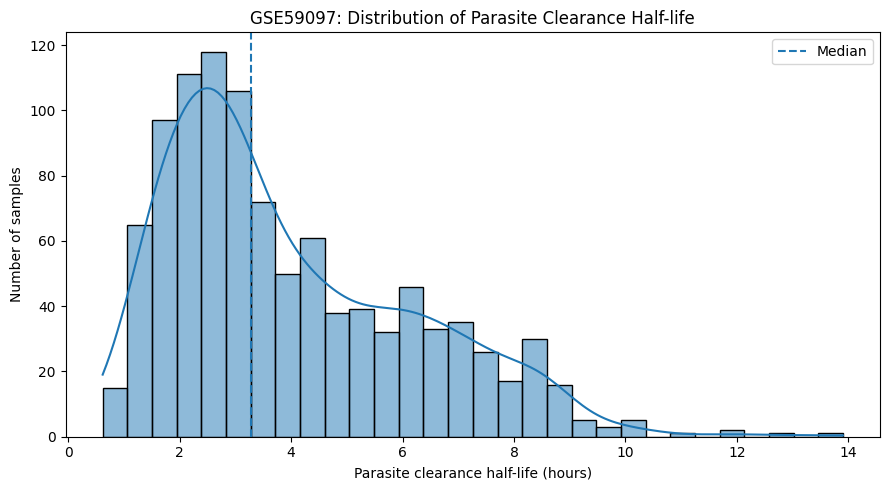

In [37]:
plt.figure(figsize=(9, 5))

sns.histplot(
    metadata["clearance_half_life"].dropna(),
    bins=30,
    kde=True
)

plt.axvline(
    metadata["clearance_half_life"].median(),
    linestyle="--",
    label="Median"
)

plt.xlabel("Parasite clearance half-life (hours)")
plt.ylabel("Number of samples")
plt.title("GSE59097: Distribution of Parasite Clearance Half-life")
plt.legend()
plt.tight_layout()
plt.show()

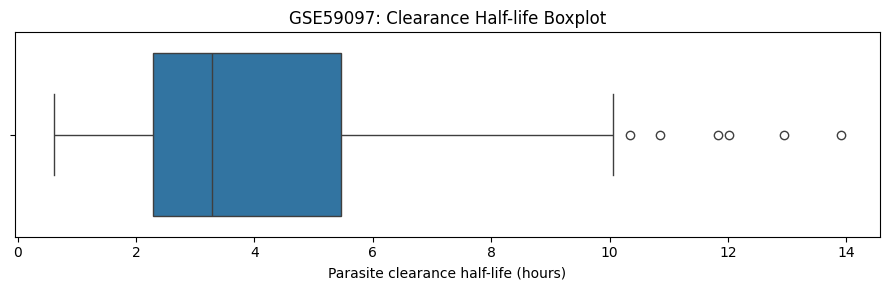

In [38]:
plt.figure(figsize=(9, 3))

sns.boxplot(
    x=metadata["clearance_half_life"].dropna()
)

plt.xlabel("Parasite clearance half-life (hours)")
plt.title("GSE59097: Clearance Half-life Boxplot")
plt.tight_layout()
plt.show()


In [39]:
# Calculate the interquartile range (IQR)

Q1 = metadata["clearance_half_life"].quantile(0.25)
Q3 = metadata["clearance_half_life"].quantile(0.75)

IQR = Q3 - Q1

# Calculate the upper and lower limits
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 2.294
Q3: 5.468
IQR: 3.174
Lower bound: -2.467
Upper bound: 10.229


In [40]:
# Identify potential outliers

outliers = metadata[
    (metadata["clearance_half_life"] < lower_bound) |
    (metadata["clearance_half_life"] > upper_bound)
]

print("Number of potential outliers:", len(outliers))

display(
    outliers[
        ["GSM_ID", "patient sample id",
         "geographic origin", "clearance_half_life"]
    ].sort_values(
        "clearance_half_life",
        ascending=False
    )
)

Number of potential outliers: 6


,GSM_ID,patient sample id,geographic origin,clearance_half_life
894,GSM1428259,TH005-024,"Sisakhet, Thailand",13.905
893,GSM1428258,TH005-023,"Sisakhet, Thailand",12.948
892,GSM1428257,TH005-022,"Sisakhet, Thailand",12.015
187,GSM1427552,KH001-029,"Pursat, Cambodia",11.839
885,GSM1428250,TH005-013,"Sisakhet, Thailand",10.855
890,GSM1428255,TH005-020,"Sisakhet, Thailand",10.354


In [41]:
# Standardise column names
metadata.columns = (
    metadata.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print(metadata.columns.tolist())

['gsm_id', 'title', 'culture', 'stage', 'patient_sample_id', 'geographic_origin', 'barcode', 'timepoint', 'parasite_clearance_halflife_upon_artemisinin_treatment_(h)', 'clearance_half_life']


In [42]:
location_summary = (
    metadata
    .groupby("geographic_origin")["clearance_half_life"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
    .sort_values("median", ascending=False)
)

display(location_summary)

,count,mean,median,std,min,max
geographic_origin,,,,,,
"Sisakhet, Thailand",27,7.197,7.052,3.111,2.698,13.905
"Pailin, Cambodia",88,6.043,6.157,1.612,2.373,8.951
"Khun Han, Thailand",8,5.145,5.534,1.971,1.567,7.100
"Pursat, Cambodia",102,5.534,5.474,2.070,1.692,11.839
"Ranong, Thailand",21,5.258,5.162,1.890,2.355,9.477
"Mae Sot, Thailand",119,5.095,4.912,2.022,0.617,10.059
"Binh Phuoc, Vietnam",112,3.892,3.124,2.277,0.762,8.946
"Shwe Kyin, Myanmar",81,3.580,3.115,1.662,1.278,8.582
"Rattanakiri, Cambodia",106,3.030,3.024,1.151,0.666,8.569


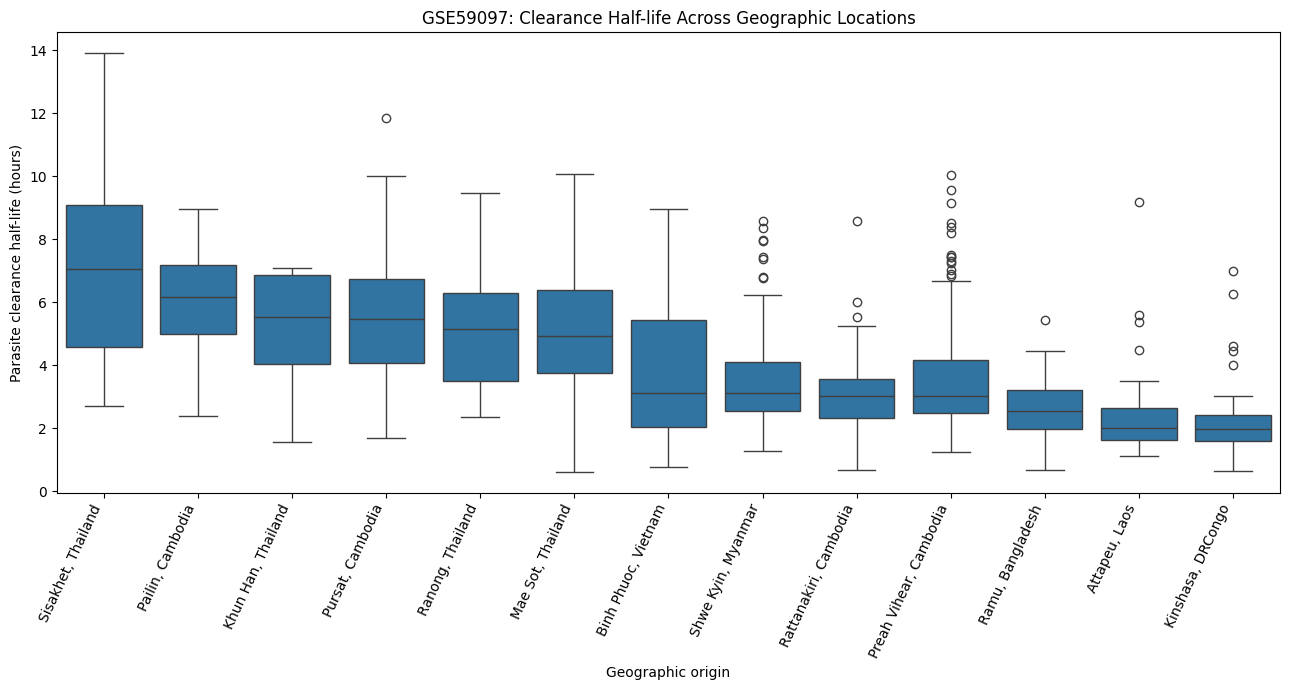

In [43]:
# Visualise clearance half-life by geographic origin

import matplotlib.pyplot as plt
import seaborn as sns

# Order locations by median clearance half-life
location_order = (
    metadata.groupby("geographic_origin")["clearance_half_life"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(13, 7))

sns.boxplot(
    data=metadata,
    x="geographic_origin",
    y="clearance_half_life",
    order=location_order
)

plt.xticks(rotation=65, ha="right")
plt.xlabel("Geographic origin")
plt.ylabel("Parasite clearance half-life (hours)")
plt.title("GSE59097: Clearance Half-life Across Geographic Locations")
plt.tight_layout()
plt.show()

In [44]:
# Examine categorical metadata variables

categorical_columns = [
    "culture",
    "stage",
    "timepoint",
    "geographic_origin"
]

for column in categorical_columns:
    print(f"\n{'='*50}")
    print(f"Column: {column}")
    print(f"Unique values: {metadata[column].nunique()}")
    print(metadata[column].value_counts(dropna=False))


Column: culture
Unique values: 1
culture
in vivo    1043
Name: count, dtype: int64

Column: stage
Unique values: 1
stage
blood    1043
Name: count, dtype: int64

Column: timepoint
Unique values: 1
timepoint
prior to artemisinin combination therapy (ACT)    1043
Name: count, dtype: int64

Column: geographic_origin
Unique values: 13
geographic_origin
Mae Sot, Thailand         121
Preah Vihear, Cambodia    116
Kinshasa, DRCongo         114
Binh Phuoc, Vietnam       113
Rattanakiri, Cambodia     106
Pursat, Cambodia          103
Pailin, Cambodia           91
Attapeu, Laos              87
Shwe Kyin, Myanmar         82
Ramu, Bangladesh           53
Sisakhet, Thailand         27
Ranong, Thailand           21
Khun Han, Thailand          9
Name: count, dtype: int64


In [46]:
print("Metadata columns:")
print(metadata.columns.tolist())

print("\nIndex name:")
print(metadata.index.name)

print("\nFirst 5 rows:")
display(metadata.head())

Metadata columns:
['gsm_id', 'title', 'culture', 'stage', 'patient_sample_id', 'geographic_origin', 'barcode', 'timepoint', 'parasite_clearance_halflife_upon_artemisinin_treatment_(h)', 'clearance_half_life']

Index name:
None

First 5 rows:


,gsm_id,title,culture,stage,patient_sample_id,geographic_origin,barcode,timepoint,parasite_clearance_halflife_upon_artemisinin_treatment_(h),clearance_half_life
0,GSM1427365,BD001-001-219888,in vivo,blood,BD001-001,"Ramu, Bangladesh",219888,prior to artemisinin combination therapy (ACT),4.142h,4.142
1,GSM1427366,BD001-002-219908,in vivo,blood,BD001-002,"Ramu, Bangladesh",219908,prior to artemisinin combination therapy (ACT),1.687h,1.687
2,GSM1427367,BD001-003-219688,in vivo,blood,BD001-003,"Ramu, Bangladesh",219688,prior to artemisinin combination therapy (ACT),0.684h,0.684
3,GSM1427368,BD001-004-219590,in vivo,blood,BD001-004,"Ramu, Bangladesh",219590,prior to artemisinin combination therapy (ACT),2.081h,2.081
4,GSM1427369,BD001-005-219618,in vivo,blood,BD001-005,"Ramu, Bangladesh",219618,prior to artemisinin combination therapy (ACT),1.756h,1.756


In [47]:
# Find the original clearance half-life column
clearance_col = next(
    col for col in metadata.columns
    if "parasite_clearance" in col.lower()
)

# Rename columns to simpler, consistent names
metadata = metadata.rename(columns={
    "gsm_id": "GSM_ID",
    clearance_col: "clearance_half_life"
})

# Verify the changes
print("Updated columns:")
print(metadata.columns.tolist())

print("\nClearance half-life summary:")
display(metadata["clearance_half_life"].describe())

Updated columns:
['GSM_ID', 'title', 'culture', 'stage', 'patient_sample_id', 'geographic_origin', 'barcode', 'timepoint', 'clearance_half_life', 'clearance_half_life']

Clearance half-life summary:


,clearance_half_life
count,1025.000000
mean,3.980972
std,2.223613
min,0.617000
25%,2.294000
50%,3.276000
75%,5.468000
max,13.905000


In [48]:
# Find duplicated column names
duplicate_names = metadata.columns[
    metadata.columns.duplicated(keep=False)
].unique()

print("Duplicate column names:", duplicate_names.tolist())

# Compare the duplicated columns
for col in duplicate_names:
    positions = [
        i for i, name in enumerate(metadata.columns)
        if name == col
    ]

    print(f"\nColumn: {col}")

    for position in positions:
        series = metadata.iloc[:, position]

        print(
            f"Position {position}: "
            f"Available={series.notna().sum()}, "
            f"Missing={series.isna().sum()}"
        )

    if len(positions) == 2:
        first = metadata.iloc[:, positions[0]]
        second = metadata.iloc[:, positions[1]]

        print("Are both columns identical?", first.equals(second))

Duplicate column names: ['clearance_half_life']

Column: clearance_half_life
Position 8: Available=1043, Missing=0
Position 9: Available=1025, Missing=18
Are both columns identical? False


In [49]:
# Display both columns side by side
comparison = pd.DataFrame({
    "GSM_ID": metadata["GSM_ID"],
    "clearance_column_1": metadata.iloc[:, 8],
    "clearance_column_2": metadata.iloc[:, 9]
})

display(comparison.head(20))

print("\nFirst column data type:", metadata.iloc[:, 8].dtype)
print("Second column data type:", metadata.iloc[:, 9].dtype)

print("\nFirst column unique values:")
print(metadata.iloc[:, 8].value_counts(dropna=False).head(10))

print("\nSecond column unique values:")
print(metadata.iloc[:, 9].value_counts(dropna=False).head(10))

,GSM_ID,clearance_column_1,clearance_column_2
0,GSM1427365,4.142h,4.142
1,GSM1427366,1.687h,1.687
2,GSM1427367,0.684h,0.684
3,GSM1427368,2.081h,2.081
4,GSM1427369,1.756h,1.756
5,GSM1427370,0.866h,0.866
6,GSM1427371,2.445h,2.445
7,GSM1427372,2.713h,2.713
8,GSM1427373,1.372h,1.372
9,GSM1427374,2.365h,2.365



First column data type: object
Second column data type: float64

First column unique values:
clearance_half_life
NA        18
2.164h     3
2.199h     3
1.840h     2
1.973h     2
2.393h     2
2.498h     2
3.029h     2
1.891h     2
8.684h     2
Name: count, dtype: int64

Second column unique values:
clearance_half_life
NaN      18
2.164     3
2.199     3
1.840     2
1.973     2
2.393     2
2.498     2
3.029     2
1.891     2
8.684     2
Name: count, dtype: int64


In [50]:
# Convert the original text column into numeric values
original_numeric = pd.to_numeric(
    metadata.iloc[:, 8].str.replace("h", "", regex=False),
    errors="coerce"
)

# Get the already numeric column
converted_numeric = metadata.iloc[:, 9]

# Compare both columns
comparison_result = np.isclose(
    original_numeric,
    converted_numeric,
    equal_nan=True
)

print("Total samples:", len(metadata))
print("Matching measurements:", comparison_result.sum())
print("Non-matching measurements:", (~comparison_result).sum())

Total samples: 1043
Matching measurements: 1043
Non-matching measurements: 0


In [51]:
# Preserve the original text values
metadata = metadata.rename(columns={
    "clearance_half_life": "clearance_half_life_original"
})

# Rename the second, numeric column
metadata = metadata.rename(columns={
    metadata.columns[9]: "clearance_half_life"
})

# Verify the result
print("Updated columns:")
print(metadata.columns.tolist())

print("\nDataset dimensions:", metadata.shape)

print("\nMissing numeric clearance values:",
      metadata["clearance_half_life"].isna().sum())

print("\nNumeric clearance summary:")
display(metadata["clearance_half_life"].describe())

Updated columns:
['GSM_ID', 'title', 'culture', 'stage', 'patient_sample_id', 'geographic_origin', 'barcode', 'timepoint', 'clearance_half_life', 'clearance_half_life']

Dataset dimensions: (1043, 10)

Missing numeric clearance values: clearance_half_life     0
clearance_half_life    18
dtype: int64

Numeric clearance summary:


,clearance_half_life
count,1025.000000
mean,3.980972
std,2.223613
min,0.617000
25%,2.294000
50%,3.276000
75%,5.468000
max,13.905000


In [53]:
# Extract the two duplicated columns by position
column_1 = metadata.iloc[:, 8]
column_2 = metadata.iloc[:, 9]

# Convert the original text values into numbers
column_1_numeric = pd.to_numeric(
    column_1.astype(str).str.replace("h", "", regex=False).str.strip(),
    errors="coerce"
)

# Convert the second column into numbers
column_2_numeric = pd.to_numeric(
    column_2,
    errors="coerce"
)

# Compare all measurements
matches = np.isclose(
    column_1_numeric,
    column_2_numeric,
    equal_nan=True
)

print("Total samples:", len(metadata))
print("Matching measurements:", matches.sum())
print("Non-matching measurements:", (~matches).sum())

print("\nMissing values in column 1:", column_1_numeric.isna().sum())
print("Missing values in column 2:", column_2_numeric.isna().sum())

Total samples: 1043
Matching measurements: 1043
Non-matching measurements: 0

Missing values in column 1: 18
Missing values in column 2: 18


In [54]:
# Keep the original text values for reference
raw_clearance = metadata.iloc[:, 8].astype("string").str.strip()

# Convert the original text values into numbers
clean_clearance = pd.to_numeric(
    raw_clearance.str.replace(r"h$", "", regex=True),
    errors="coerce"
)

# Remove duplicate column names
metadata = metadata.loc[:, ~metadata.columns.duplicated()].copy()

# Add the original and clean versions
metadata["clearance_half_life_original"] = raw_clearance
metadata["clearance_half_life"] = clean_clearance

# Check the result
print("Total samples:", len(metadata))
print("Valid clearance values:", metadata["clearance_half_life"].notna().sum())
print("Missing clearance values:", metadata["clearance_half_life"].isna().sum())
print("Duplicate column names:", metadata.columns[metadata.columns.duplicated()].tolist())

Total samples: 1043
Valid clearance values: 1025
Missing clearance values: 18
Duplicate column names: []


In [55]:
# Inspect the first three samples
for gsm_id, gsm in list(gse.gsms.items())[:3]:
    print("GSM ID:", gsm_id)
    print("Table shape:", gsm.table.shape)
    print("Columns:", gsm.table.columns.tolist())
    print(gsm.table.head(3))
    print("-" * 60)

GSM ID: GSM1427365
Table shape: (0, 0)
Columns: []
Empty DataFrame
Columns: []
Index: []
------------------------------------------------------------
GSM ID: GSM1427366
Table shape: (0, 0)
Columns: []
Empty DataFrame
Columns: []
Index: []
------------------------------------------------------------
GSM ID: GSM1427367
Table shape: (0, 0)
Columns: []
Empty DataFrame
Columns: []
Index: []
------------------------------------------------------------


In [56]:
gse = GEOparse.get_GEO(
    "GSE59097",
    destdir="data/raw",
    how="full"
)

print("Samples:", len(gse.gsms))
print("Platforms:", len(gse.gpls))

17-Nov-2026 06:26:10 DEBUG utils - Directory data/raw already exists. Skipping.
DEBUG:GEOparse:Directory data/raw already exists. Skipping.
17-Nov-2026 06:26:10 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE59nnn/GSE59097/soft/GSE59097_family.soft.gz to data/raw/GSE59097_family.soft.gz
INFO:GEOparse:Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE59nnn/GSE59097/soft/GSE59097_family.soft.gz to data/raw/GSE59097_family.soft.gz
100%|██████████| 94.8M/94.8M [00:28<00:00, 3.46MB/s]
17-Nov-2026 06:26:38 DEBUG downloader - Size validation passed
DEBUG:GEOparse:Size validation passed
17-Nov-2026 06:26:38 DEBUG downloader - Moving /tmp/tmpx_q4qxqo to /content/data/raw/GSE59097_family.soft.gz
DEBUG:GEOparse:Moving /tmp/tmpx_q4qxqo to /content/data/raw/GSE59097_family.soft.gz
17-Nov-2026 06:26:39 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE59nnn/GSE59097/soft/GSE59097_family.soft.gz
DEBUG:GEOparse:Successfully downloaded ftp://ft

Samples: 1043
Platforms: 1


In [57]:
print("Number of samples:", len(gse.gsms))
print("Number of platforms:", len(gse.gpls))

# Inspect the first three samples
for gsm_id, gsm in list(gse.gsms.items())[:3]:
    print("\nGSM ID:", gsm_id)
    print("Expression table shape:", gsm.table.shape)
    print("Columns:", gsm.table.columns.tolist())
    print(gsm.table.head(3))

# Inspect platform information
for gpl_id, gpl in gse.gpls.items():
    print("\nPlatform ID:", gpl_id)
    print("Platform table shape:", gpl.table.shape)
    print(gpl.table.head(3))

Number of samples: 1043
Number of platforms: 1

GSM ID: GSM1427365
Expression table shape: (11005, 2)
Columns: ['ID_REF', 'VALUE']
          ID_REF     VALUE
0  ac11rRNA18s_0  0.029925
1  ac11rRNA18s_1  0.042050
2  ac11rRNA28s_0  0.345643

GSM ID: GSM1427366
Expression table shape: (11005, 2)
Columns: ['ID_REF', 'VALUE']
          ID_REF     VALUE
0  ac11rRNA18s_0 -0.095802
1  ac11rRNA18s_1 -0.116750
2  ac11rRNA28s_0  0.046943

GSM ID: GSM1427367
Expression table shape: (11005, 2)
Columns: ['ID_REF', 'VALUE']
          ID_REF     VALUE
0  ac11rRNA18s_0 -0.140659
1  ac11rRNA18s_1 -0.217292
2  ac11rRNA28s_0 -0.098705

Platform ID: GPL18893
Platform table shape: (11372, 7)
            ID                                           SEQUENCE  \
0  aPFA0005w_0  AACCTAAAGAAAAAACCTGTGGAAAAACAAAGACATACGATCCTAA...   
1  aPFA0005w_1  TATATGAATCAACCGACTATGACGATGAAGAAAAAGATCCACAAGA...   
2  aPFA0005w_2  TATGAAGAACAAAAAACAAAATGCCAAAAGGAAAGTAAGAGTGCTA...   

    CHROMOSOME  POSITION            ORF   OR

In [58]:
# Inspect all platform annotation columns
gpl = list(gse.gpls.values())[0]

print("Platform ID:", gpl.name)
print("\nAnnotation columns:")
print(gpl.table.columns.tolist())

print("\nAnnotation information:")
display(gpl.table.head(10))

print("\nMissing values per column:")
display(gpl.table.isna().sum())

Platform ID: GPL18893

Annotation columns:
['ID', 'SEQUENCE', 'CHROMOSOME', 'POSITION', 'ORF', 'ORF_old', 'SPOT_ID']

Annotation information:


,ID,SEQUENCE,CHROMOSOME,POSITION,ORF,ORF_old,SPOT_ID
0,aPFA0005w_0,AACCTAAAGAAAAAACCTGTGGAAAAACAAAGACATACGATCCTAA...,Pf3D7_01_v3,31035.0,PF3D7_0100100,PFA0005w,NaN
1,aPFA0005w_1,TATATGAATCAACCGACTATGACGATGAAGAAAAAGATCCACAAGA...,Pf3D7_01_v3,32538.0,PF3D7_0100100,PFA0005w,NaN
2,aPFA0005w_2,TATGAAGAACAAAAAACAAAATGCCAAAAGGAAAGTAAGAGTGCTA...,Pf3D7_01_v3,33368.0,PF3D7_0100100,PFA0005w,NaN
3,aPFA0005w_3,AACATTTGTCCAACAAAACAACCACAACCAGAGAAAGAAGACGGTT...,Pf3D7_01_v3,34424.0,PF3D7_0100100,PFA0005w,NaN
4,aPFA0010c_0,GCAGGGATTGAAGGATTAAGAGATTTTTCTGGTCTGGGTAAATTAA...,Pf3D7_01_v3,39350.0,PF3D7_0100200,PFA0010c,NaN
5,aPFA0015c_1,TATATGGAGGGTGATAGTGGAGATGAAGATAAATATATTGGAAACA...,Pf3D7_01_v3,43407.0,PF3D7_0100300,PFA0015c,NaN
6,aPFA0015c_0,TATAAAAAGAAGAATTGATGGTGGTGATATTGAGAATTTGATTTTG...,Pf3D7_01_v3,45629.0,PF3D7_0100300,PFA0015c,NaN
7,aPFA0020w_0,CATCAATTACATCACGTCATATACAAACTACCAGATTATTATGCGA...,Pf3D7_01_v3,50591.0,PF3D7_0100400,PFA0020w,NaN
8,aPFA0020w_1,GTGATCCTTTTTGCAATTTGGTTCATTCAAATCTTCAAGGTAGTTT...,Pf3D7_01_v3,51290.0,PF3D7_0100400,PFA0020w,NaN
9,aPFA0025c_0,TGCGTTTGCTACGTTGAGTTACTTTTTACTAAAGGTAAATGGATGT...,Pf3D7_01_v3,53173.0,PF3D7_0100500,PFA0025c,NaN



Missing values per column:


,0
ID,0
SEQUENCE,0
CHROMOSOME,1076
POSITION,1158
ORF,1158
ORF_old,1159
SPOT_ID,10182


In [59]:
# Basic platform annotation statistics
annotation = gpl.table.copy()

print("Total annotation records:", len(annotation))
print("Unique probe IDs:", annotation["ID"].nunique())
print("Unique ORF identifiers:", annotation["ORF"].nunique())

print("\nMissing ORF identifiers:", annotation["ORF"].isna().sum())

# How many probes map to each ORF?
probes_per_gene = annotation.groupby("ORF")["ID"].nunique()

print("\nProbe-to-gene mapping:")
print("Genes with at least one probe:", len(probes_per_gene))
print("Genes with multiple probes:", (probes_per_gene > 1).sum())
print("Maximum probes assigned to one gene:", probes_per_gene.max())

print("\nDistribution of probes per gene:")
display(probes_per_gene.value_counts().sort_index().head(15))

Total annotation records: 11372
Unique probe IDs: 11372
Unique ORF identifiers: 5287

Missing ORF identifiers: 1158

Probe-to-gene mapping:
Genes with at least one probe: 5287
Genes with multiple probes: 3166
Maximum probes assigned to one gene: 16

Distribution of probes per gene:


,count
ID,
1,2121
2,2345
3,414
4,197
5,95
6,47
7,23
8,10
9,13


Sample ID: GSM1427365
Total measurements: 11005
Missing values: 509


,VALUE
count,10496.000000
mean,-0.026806
std,0.806089
min,-3.059515
25%,-0.555150
50%,-0.066725
75%,0.461600
max,4.072622


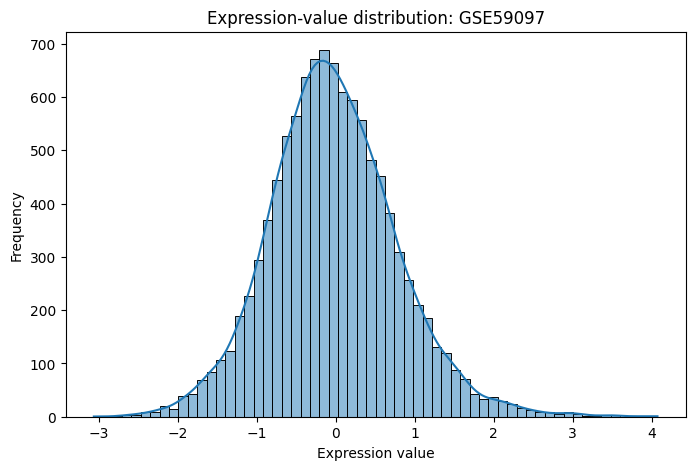

In [60]:
# Select the first sample
first_gsm = list(gse.gsms.values())[0]

# Extract expression values
expression_values = pd.to_numeric(
    first_gsm.table["VALUE"],
    errors="coerce"
)

# Basic information
print("Sample ID:", first_gsm.name)
print("Total measurements:", len(expression_values))
print("Missing values:", expression_values.isna().sum())

# Descriptive statistics
display(expression_values.describe())

# Plot the distribution
plt.figure(figsize=(8, 5))
sns.histplot(expression_values.dropna(), bins=60, kde=True)

plt.xlabel("Expression value")
plt.ylabel("Frequency")
plt.title("Expression-value distribution: GSE59097")
plt.show()

In [61]:
# Collect expression values from every sample
sample_stats = []

for gsm_id, gsm in gse.gsms.items():

    values = pd.to_numeric(
        gsm.table["VALUE"],
        errors="coerce"
    ).dropna()

    sample_stats.append({
        "GSM_ID": gsm_id,
        "mean": values.mean(),
        "median": values.median(),
        "std": values.std(),
        "min": values.min(),
        "max": values.max()
    })

sample_stats = pd.DataFrame(sample_stats)

print("Number of samples analysed:", len(sample_stats))

display(sample_stats.describe())

Number of samples analysed: 1043


,mean,median,std,min,max
count,1043.000000,1043.000000,1043.000000,1043.000000,1043.000000
mean,-0.014460,-0.017593,0.893568,-3.508280,4.083410
std,0.048332,0.055945,0.102341,0.564162,0.688079
min,-0.262535,-0.230294,0.532201,-6.146470,2.599708
25%,-0.043871,-0.051196,0.832579,-3.797149,3.597745
50%,-0.015677,-0.012117,0.899832,-3.460242,4.034898
75%,0.014424,0.018999,0.964623,-3.142848,4.482179
max,0.198660,0.196530,1.173215,-2.093903,7.600102


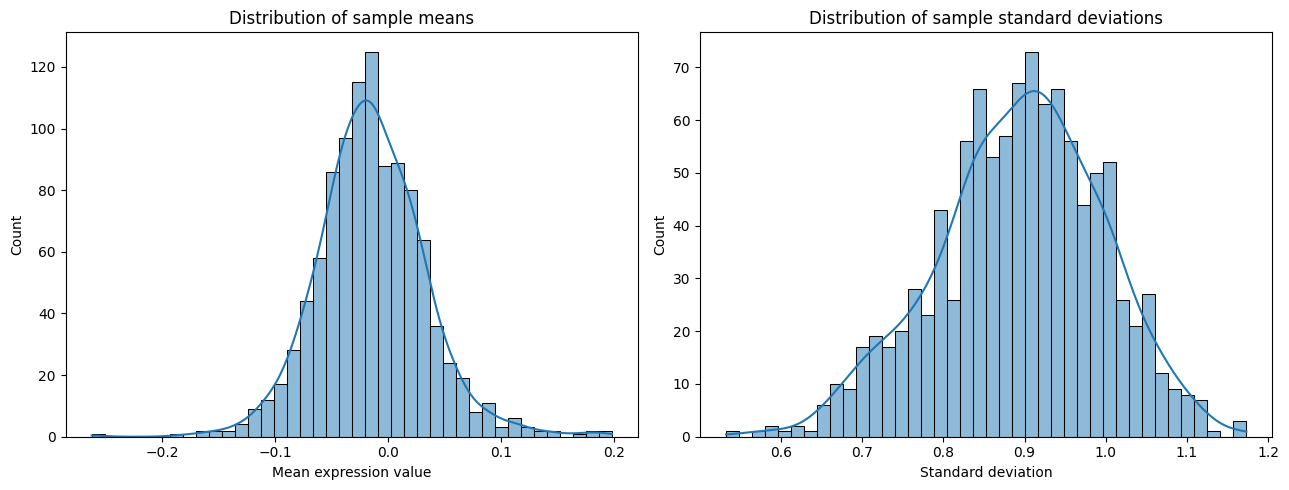

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Distribution of sample means
sns.histplot(
    sample_stats["mean"],
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of sample means")
axes[0].set_xlabel("Mean expression value")

# Distribution of sample standard deviations
sns.histplot(
    sample_stats["std"],
    bins=40,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribution of sample standard deviations")
axes[1].set_xlabel("Standard deviation")

plt.tight_layout()
plt.show()

In [63]:
# Find the 10 samples with the highest expression variability
highest_variability = sample_stats.sort_values(
    by="std",
    ascending=False
).head(10)

display(highest_variability)

,GSM_ID,mean,median,std,min,max
521,GSM1427886,0.181439,0.196530,1.173215,-3.929832,3.988681
285,GSM1427650,-0.041884,-0.001860,1.164235,-4.472011,4.185566
520,GSM1427885,0.166227,0.193346,1.164201,-4.022278,4.202393
900,GSM1428265,-0.095006,-0.097711,1.133850,-4.226811,3.757747
500,GSM1427865,-0.136244,-0.126929,1.116335,-3.923420,3.663339
1025,GSM1428390,-0.010875,0.040345,1.116139,-3.925010,4.332009
670,GSM1428035,0.012103,0.106469,1.115672,-4.189304,3.909320
154,GSM1427519,-0.183195,-0.230294,1.115536,-5.151253,4.592480
847,GSM1428212,-0.007149,-0.042276,1.113704,-3.944300,5.873350
970,GSM1428335,-0.037934,0.017924,1.113284,-4.142452,4.093531


In [65]:
print("Current metadata columns:")
print(metadata.columns.tolist())

print("\nFirst five rows:")
display(metadata.head())

Current metadata columns:
['GSM_ID', 'title', 'culture', 'stage', 'patient_sample_id', 'geographic_origin', 'barcode', 'timepoint', 'clearance_half_life', 'clearance_half_life_original']

First five rows:


,GSM_ID,title,culture,stage,patient_sample_id,geographic_origin,barcode,timepoint,clearance_half_life,clearance_half_life_original
0,GSM1427365,BD001-001-219888,in vivo,blood,BD001-001,"Ramu, Bangladesh",219888,prior to artemisinin combination therapy (ACT),4.142,4.142h
1,GSM1427366,BD001-002-219908,in vivo,blood,BD001-002,"Ramu, Bangladesh",219908,prior to artemisinin combination therapy (ACT),1.687,1.687h
2,GSM1427367,BD001-003-219688,in vivo,blood,BD001-003,"Ramu, Bangladesh",219688,prior to artemisinin combination therapy (ACT),0.684,0.684h
3,GSM1427368,BD001-004-219590,in vivo,blood,BD001-004,"Ramu, Bangladesh",219590,prior to artemisinin combination therapy (ACT),2.081,2.081h
4,GSM1427369,BD001-005-219618,in vivo,blood,BD001-005,"Ramu, Bangladesh",219618,prior to artemisinin combination therapy (ACT),1.756,1.756h


In [66]:
# Get the 10 most variable sample IDs
top_ids = highest_variability["GSM_ID"].tolist()

# Select their metadata using the correct column name
top_sample_metadata = metadata[
    metadata["GSM_ID"].isin(top_ids)
].copy()

# Merge metadata with expression variability statistics
result = top_sample_metadata.merge(
    highest_variability[["GSM_ID", "std", "mean"]],
    on="GSM_ID",
    how="left"
)

# Display relevant information
display(
    result[
        [
            "GSM_ID",
            "geographic_origin",
            "culture",
            "stage",
            "timepoint",
            "clearance_half_life",
            "std",
            "mean"
        ]
    ]
)

,GSM_ID,geographic_origin,culture,stage,timepoint,clearance_half_life,std,mean
0,GSM1427519,"Kinshasa, DRCongo",in vivo,blood,prior to artemisinin combination therapy (ACT),1.321,1.115536,-0.183195
1,GSM1427650,"Preah Vihear, Cambodia",in vivo,blood,prior to artemisinin combination therapy (ACT),2.707,1.164235,-0.041884
2,GSM1427865,"Pailin, Cambodia",in vivo,blood,prior to artemisinin combination therapy (ACT),<NA>,1.116335,-0.136244
3,GSM1427885,"Pailin, Cambodia",in vivo,blood,prior to artemisinin combination therapy (ACT),7.307,1.164201,0.166227
4,GSM1427886,"Pailin, Cambodia",in vivo,blood,prior to artemisinin combination therapy (ACT),6.466,1.173215,0.181439
5,GSM1428035,"Shwe Kyin, Myanmar",in vivo,blood,prior to artemisinin combination therapy (ACT),2.556,1.115672,0.012103
6,GSM1428212,"Mae Sot, Thailand",in vivo,blood,prior to artemisinin combination therapy (ACT),2.595,1.113704,-0.007149
7,GSM1428265,"Khun Han, Thailand",in vivo,blood,prior to artemisinin combination therapy (ACT),5.271,1.133850,-0.095006
8,GSM1428335,"Binh Phuoc, Vietnam",in vivo,blood,prior to artemisinin combination therapy (ACT),5.296,1.113284,-0.037934
9,GSM1428390,"Binh Phuoc, Vietnam",in vivo,blood,prior to artemisinin combination therapy (ACT),8.946,1.116139,-0.010875


In [67]:
# Check patient-level sample uniqueness

print("Total GEO samples:", len(metadata))

print(
    "Unique patient sample IDs:",
    metadata["patient_sample_id"].nunique()
)

print(
    "Missing patient sample IDs:",
    metadata["patient_sample_id"].isna().sum()
)

# Find patient IDs appearing more than once
patient_counts = metadata["patient_sample_id"].value_counts()

repeated_patients = patient_counts[patient_counts > 1]

print("\nRepeated patient IDs:", len(repeated_patients))
print("Records belonging to repeated IDs:", repeated_patients.sum())

display(repeated_patients.head(15))

Total GEO samples: 1043
Unique patient sample IDs: 1033
Missing patient sample IDs: 0

Repeated patient IDs: 10
Records belonging to repeated IDs: 20


,count
patient_sample_id,
KH004-084,2
KH004-073,2
TH004-028,2
TH004-029,2
TH004-089,2
TH004-088,2
TH004-087,2
TH004-086,2
MM001-005,2


In [68]:
# Identify repeated patient IDs
repeated_ids = patient_counts[patient_counts > 1].index

# Extract all records belonging to these patients
repeated_patient_records = metadata[
    metadata["patient_sample_id"].isin(repeated_ids)
].copy()

# Sort by patient ID
repeated_patient_records = repeated_patient_records.sort_values(
    "patient_sample_id"
)

# Display relevant information
display(
    repeated_patient_records[
        [
            "patient_sample_id",
            "GSM_ID",
            "title",
            "barcode",
            "geographic_origin",
            "timepoint",
            "clearance_half_life"
        ]
    ]
)

,patient_sample_id,GSM_ID,title,barcode,geographic_origin,timepoint,clearance_half_life
553,KH004-073,GSM1427918,KH004-073-209100,209100,"Pailin, Cambodia",prior to artemisinin combination therapy (ACT),3.937
554,KH004-073,GSM1427919,KH004-073-222060,222060,"Pailin, Cambodia",prior to artemisinin combination therapy (ACT),3.937
565,KH004-084,GSM1427930,KH004-084-234600,234600,"Pailin, Cambodia",prior to artemisinin combination therapy (ACT),8.203
566,KH004-084,GSM1427931,KH004-084-235312,235312,"Pailin, Cambodia",prior to artemisinin combination therapy (ACT),8.203
674,MM001-005,GSM1428039,MM001-005-210248,210248,"Shwe Kyin, Myanmar",prior to artemisinin combination therapy (ACT),2.843
675,MM001-005,GSM1428040,MM001-005-210634,210634,"Shwe Kyin, Myanmar",prior to artemisinin combination therapy (ACT),2.843
676,MM001-006,GSM1428041,MM001-006-210247,210247,"Shwe Kyin, Myanmar",prior to artemisinin combination therapy (ACT),3.725
677,MM001-006,GSM1428042,MM001-006-210635,210635,"Shwe Kyin, Myanmar",prior to artemisinin combination therapy (ACT),3.725
780,TH004-028,GSM1428145,TH004-028-197533,197344,"Mae Sot, Thailand",prior to artemisinin combination therapy (ACT),4.22
779,TH004-028,GSM1428144,TH004-028-197344,197533,"Mae Sot, Thailand",prior to artemisinin combination therapy (ACT),4.22


In [69]:
# Compare expression profiles for the 10 repeated patient IDs

pair_results = []

for patient_id in repeated_ids:

    patient_rows = metadata[
        metadata["patient_sample_id"] == patient_id
    ]

    gsm_ids = patient_rows["GSM_ID"].tolist()

    # We expect two GEO records per repeated patient
    if len(gsm_ids) != 2:
        continue

    gsm_1 = gse.gsms[gsm_ids[0]].table[["ID_REF", "VALUE"]]
    gsm_2 = gse.gsms[gsm_ids[1]].table[["ID_REF", "VALUE"]]

    # Match measurements by probe ID
    paired_values = gsm_1.merge(
        gsm_2,
        on="ID_REF",
        suffixes=("_1", "_2")
    )

    # Calculate correlation between the two expression profiles
    correlation = paired_values["VALUE_1"].corr(
        paired_values["VALUE_2"]
    )

    pair_results.append({
        "patient_sample_id": patient_id,
        "GSM_1": gsm_ids[0],
        "GSM_2": gsm_ids[1],
        "shared_probes": len(paired_values),
        "expression_correlation": correlation
    })

pair_correlations = pd.DataFrame(pair_results)

display(
    pair_correlations.sort_values(
        "expression_correlation",
        ascending=False
    )
)

,patient_sample_id,GSM_1,GSM_2,shared_probes,expression_correlation
3,TH004-029,GSM1428146,GSM1428147,11005,0.908964
6,TH004-087,GSM1428204,GSM1428205,11005,0.892643
5,TH004-088,GSM1428206,GSM1428207,11005,0.882213
0,KH004-084,GSM1427930,GSM1427931,11005,0.871661
9,MM001-006,GSM1428041,GSM1428042,11005,0.851727
8,MM001-005,GSM1428039,GSM1428040,11005,0.815846
4,TH004-089,GSM1428208,GSM1428209,11005,0.789823
7,TH004-086,GSM1428202,GSM1428203,11005,0.760084
2,TH004-028,GSM1428144,GSM1428145,11005,0.744492
1,KH004-073,GSM1427918,GSM1427919,11005,0.305142


In [70]:
# Inspect the two records belonging to KH004-073

display(
    metadata[
        metadata["patient_sample_id"] == "KH004-073"
    ][[
        "patient_sample_id",
        "GSM_ID",
        "title",
        "barcode",
        "geographic_origin",
        "timepoint",
        "clearance_half_life"
    ]]
)


,patient_sample_id,GSM_ID,title,barcode,geographic_origin,timepoint,clearance_half_life
553,KH004-073,GSM1427918,KH004-073-209100,209100,"Pailin, Cambodia",prior to artemisinin combination therapy (ACT),3.937
554,KH004-073,GSM1427919,KH004-073-222060,222060,"Pailin, Cambodia",prior to artemisinin combination therapy (ACT),3.937


In [71]:
# Compare metadata for all repeated patient IDs

repeated_ids = (
    metadata["patient_sample_id"]
    .value_counts()
    .loc[lambda x: x > 1]
    .index
)

repeated_records = metadata[
    metadata["patient_sample_id"].isin(repeated_ids)
].sort_values("patient_sample_id")

display(
    repeated_records[
        [
            "patient_sample_id",
            "GSM_ID",
            "barcode",
            "geographic_origin",
            "clearance_half_life"
        ]
    ]
)

,patient_sample_id,GSM_ID,barcode,geographic_origin,clearance_half_life
553,KH004-073,GSM1427918,209100,"Pailin, Cambodia",3.937
554,KH004-073,GSM1427919,222060,"Pailin, Cambodia",3.937
565,KH004-084,GSM1427930,234600,"Pailin, Cambodia",8.203
566,KH004-084,GSM1427931,235312,"Pailin, Cambodia",8.203
674,MM001-005,GSM1428039,210248,"Shwe Kyin, Myanmar",2.843
675,MM001-005,GSM1428040,210634,"Shwe Kyin, Myanmar",2.843
676,MM001-006,GSM1428041,210247,"Shwe Kyin, Myanmar",3.725
677,MM001-006,GSM1428042,210635,"Shwe Kyin, Myanmar",3.725
780,TH004-028,GSM1428145,197344,"Mae Sot, Thailand",4.22
779,TH004-028,GSM1428144,197533,"Mae Sot, Thailand",4.22


In [72]:
# Compare expression differences between repeated patient samples

pair_differences = []

for patient_id in repeated_ids:

    pair = metadata[
        metadata["patient_sample_id"] == patient_id
    ]

    gsm_ids = pair["GSM_ID"].tolist()

    expression_1 = gse.gsms[gsm_ids[0]].table.set_index("ID_REF")["VALUE"]
    expression_2 = gse.gsms[gsm_ids[1]].table.set_index("ID_REF")["VALUE"]

    shared = pd.concat(
        [expression_1, expression_2],
        axis=1,
        join="inner"
    ).dropna()

    mean_difference = (shared.iloc[:, 0] - shared.iloc[:, 1]).abs().mean()

    pair_differences.append({
        "patient_sample_id": patient_id,
        "GSM_1": gsm_ids[0],
        "GSM_2": gsm_ids[1],
        "mean_absolute_difference": mean_difference
    })

pair_difference_df = pd.DataFrame(pair_differences)

display(
    pair_difference_df.sort_values(
        "mean_absolute_difference",
        ascending=False
    )
)

,patient_sample_id,GSM_1,GSM_2,mean_absolute_difference
1,KH004-073,GSM1427918,GSM1427919,0.672943
7,TH004-086,GSM1428202,GSM1428203,0.484983
8,MM001-005,GSM1428039,GSM1428040,0.444711
2,TH004-028,GSM1428144,GSM1428145,0.419837
9,MM001-006,GSM1428041,GSM1428042,0.410166
4,TH004-089,GSM1428208,GSM1428209,0.367259
5,TH004-088,GSM1428206,GSM1428207,0.341897
0,KH004-084,GSM1427930,GSM1427931,0.334872
3,TH004-029,GSM1428146,GSM1428147,0.269978
6,TH004-087,GSM1428204,GSM1428205,0.246217


In [73]:
# Combine all GEO sample expression tables

expression_matrix = pd.concat(
    {
        gsm_id: gsm.table.set_index("ID_REF")["VALUE"]
        for gsm_id, gsm in gse.gsms.items()
    },
    axis=1
).T

# Convert expression values to numeric
expression_matrix = expression_matrix.apply(
    pd.to_numeric,
    errors="coerce"
)

# Display basic information
print("Expression matrix shape:", expression_matrix.shape)
print("Number of samples:", expression_matrix.shape[0])
print("Number of probes:", expression_matrix.shape[1])
print("Total missing values:", expression_matrix.isna().sum().sum())
print("Duplicate sample IDs:", expression_matrix.index.duplicated().sum())
print("Duplicate probe IDs:", expression_matrix.columns.duplicated().sum())

display(expression_matrix.iloc[:5, :5])

Expression matrix shape: (1043, 11005)
Number of samples: 1043
Number of probes: 11005
Total missing values: 488513
Duplicate sample IDs: 0
Duplicate probe IDs: 0


ID_REF,ac11rRNA18s_0,ac11rRNA18s_1,ac11rRNA28s_0,ac11rRNA28s_1,ac11rRNA28s_2
GSM1427365,0.029925,0.042050,0.345643,0.636154,0.099970
GSM1427366,-0.095802,-0.116750,0.046943,-0.056378,-0.075218
GSM1427367,-0.140659,-0.217292,-0.098705,0.073904,-0.121877
GSM1427368,-0.097585,-0.096014,-0.034291,0.078753,-0.052534
GSM1427369,-0.024673,0.050791,0.127758,0.068475,0.162942


In [74]:
# Missing values per sample
missing_per_sample = expression_matrix.isna().sum(axis=1)

# Missing values per probe
missing_per_probe = expression_matrix.isna().sum(axis=0)

print("Missing values per sample:")
display(missing_per_sample.describe())

print("\nMissing values per probe:")
display(missing_per_probe.describe())

print("\nSamples with the most missing values:")
display(missing_per_sample.sort_values(ascending=False).head(10))

print("\nProbes with the most missing values:")
display(missing_per_probe.sort_values(ascending=False).head(10))

Missing values per sample:


,0
count,1043.000000
mean,468.372963
std,361.747051
min,10.000000
25%,214.000000
50%,381.000000
75%,610.500000
max,2700.000000



Missing values per probe:


,0
count,11005.000000
mean,44.390095
std,69.790234
min,0.000000
25%,3.000000
50%,9.000000
75%,51.000000
max,377.000000



Samples with the most missing values:


,0
GSM1428071,2700
GSM1428129,2436
GSM1427371,2365
GSM1427651,2303
GSM1427415,2001
GSM1428403,1949
GSM1428176,1893
GSM1427519,1790
GSM1428282,1784
GSM1427454,1773



Probes with the most missing values:


,0
ID_REF,
aPF08_0093_1,377
aPF10_0362_1,350
aPFI0980w_1,347
bDd2ste_12,346
bDd2rif_41,340
aPF14_0039_0,338
aMAL8P1.85_0,336
bDd2rif_7,335
bDd2rif_3,335


In [75]:
# Calculate missing values for each sample
missing_by_sample = (
    expression_matrix.isna()
    .sum(axis=1)
    .rename("missing_values")
    .reset_index()
)

# Identify the sample ID column
missing_by_sample.columns = ["GSM_ID", "missing_values"]

# Attach geographic information
missing_by_origin = missing_by_sample.merge(
    metadata[["GSM_ID", "geographic_origin"]],
    on="GSM_ID",
    how="left"
)

# Calculate missingness by geographic origin
origin_missingness = (
    missing_by_origin
    .groupby("geographic_origin")["missing_values"]
    .agg(["count", "mean", "median", "std", "max"])
    .sort_values("mean", ascending=False)
)

display(origin_missingness)

,count,mean,median,std,max
geographic_origin,,,,,
"Sisakhet, Thailand",27,583.777778,499.0,301.287919,1297
"Ramu, Bangladesh",53,574.811321,475.0,475.123468,2365
"Ranong, Thailand",21,558.523810,450.0,441.303254,1784
"Khun Han, Thailand",9,531.777778,505.0,419.085247,1319
"Binh Phuoc, Vietnam",113,514.185841,431.0,401.679255,1949
"Rattanakiri, Cambodia",106,493.037736,439.0,315.307829,1369
"Mae Sot, Thailand",121,478.561983,388.0,395.627916,2436
"Preah Vihear, Cambodia",116,464.827586,372.5,348.422739,2303
"Attapeu, Laos",87,459.045977,367.0,335.403017,1589


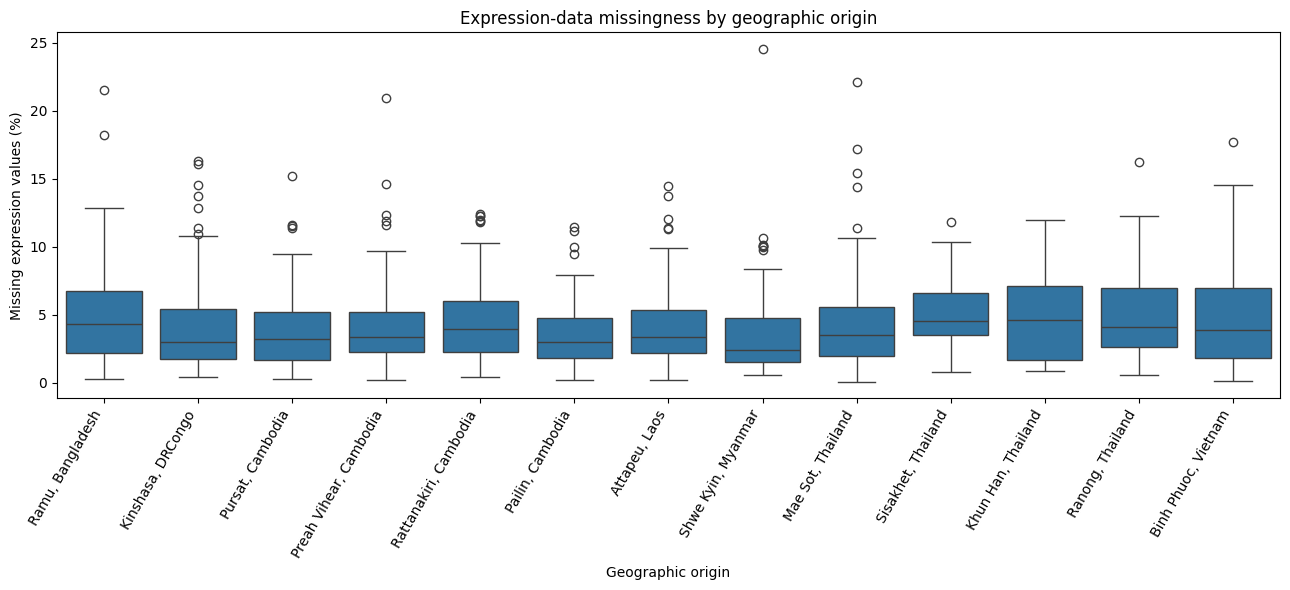

In [76]:
# Calculate percentage of missing expression values per sample
missing_by_origin["missing_percentage"] = (
    missing_by_origin["missing_values"] / expression_matrix.shape[1]
) * 100

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=missing_by_origin,
    x="geographic_origin",
    y="missing_percentage"
)

plt.xticks(rotation=60, ha="right")
plt.xlabel("Geographic origin")
plt.ylabel("Missing expression values (%)")
plt.title("Expression-data missingness by geographic origin")
plt.tight_layout()
plt.show()

,mean_expression,missing_percentage
count,11005.000000,11005.000000
mean,-0.009227,4.256001
std,0.679368,6.691298
min,-2.898327,0.000000
25%,-0.402022,0.287632
50%,0.032396,0.862895
75%,0.438183,4.889741
max,3.009915,36.145733


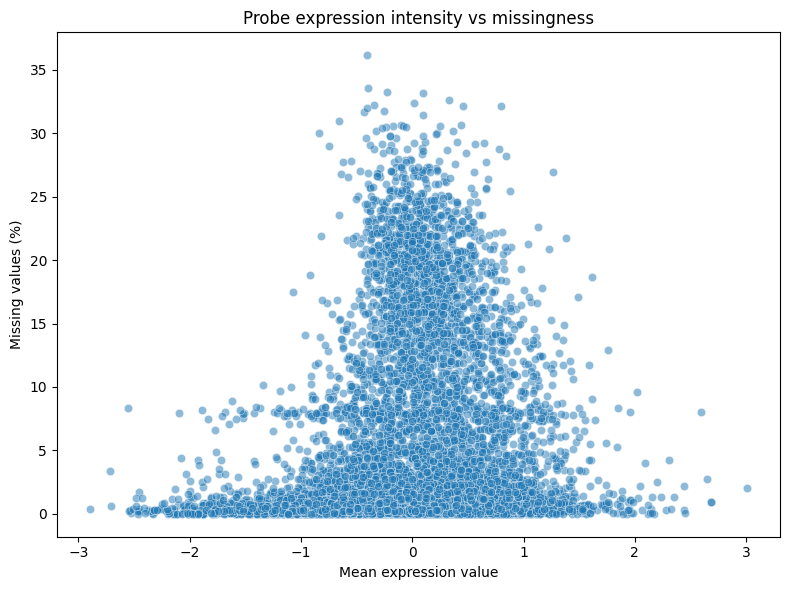

In [77]:
# Calculate average expression and missingness for each probe
probe_quality = pd.DataFrame({
    "mean_expression": expression_matrix.mean(axis=0),
    "missing_percentage": expression_matrix.isna().mean(axis=0) * 100
})

# Display the relationship
display(probe_quality.describe())

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=probe_quality,
    x="mean_expression",
    y="missing_percentage",
    alpha=0.5
)

plt.xlabel("Mean expression value")
plt.ylabel("Missing values (%)")
plt.title("Probe expression intensity vs missingness")
plt.tight_layout()
plt.show()

In [78]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    probe_quality["mean_expression"],
    probe_quality["missing_percentage"]
)

print("Spearman correlation:", round(correlation, 4))
print("P-value:", p_value)

Spearman correlation: 0.1159
P-value: 3.0512453648774845e-34


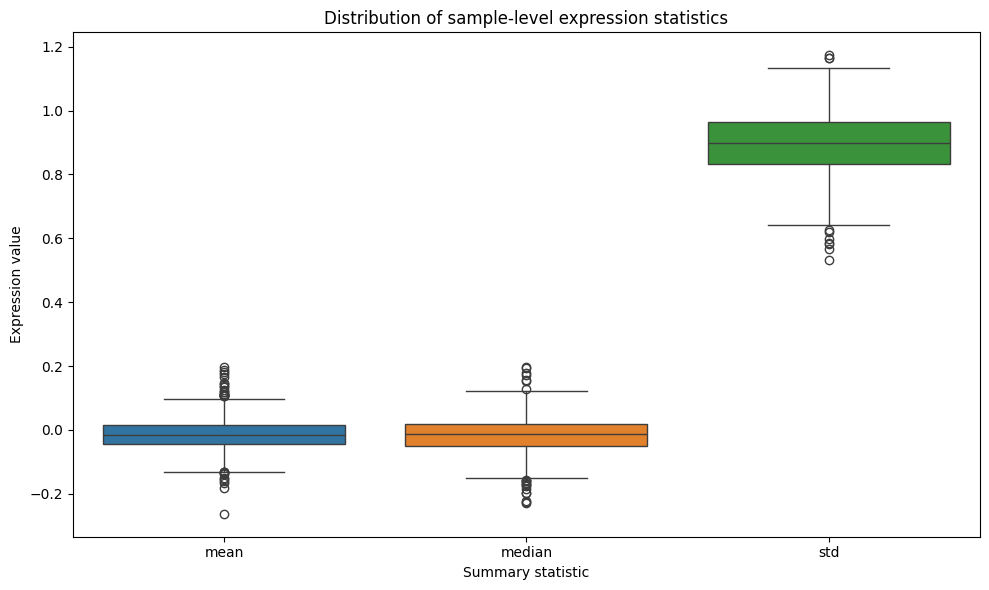

,mean,median,std
count,1043.000000,1043.000000,1043.000000
mean,-0.014460,-0.017593,0.893568
std,0.048332,0.055945,0.102341
min,-0.262535,-0.230294,0.532201
25%,-0.043871,-0.051196,0.832579
50%,-0.015677,-0.012117,0.899832
75%,0.014424,0.018999,0.964623
max,0.198660,0.196530,1.173215


In [79]:
# Calculate expression distribution statistics for each sample
sample_distribution = pd.DataFrame({
    "mean": expression_matrix.mean(axis=1),
    "median": expression_matrix.median(axis=1),
    "std": expression_matrix.std(axis=1)
})

# Visualize sample-level expression distributions
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=sample_distribution[["mean", "median", "std"]]
)

plt.title("Distribution of sample-level expression statistics")
plt.ylabel("Expression value")
plt.xlabel("Summary statistic")

plt.tight_layout()
plt.show()

display(sample_distribution.describe())

In [80]:
# Overall expression-value distribution
values = expression_matrix.to_numpy().flatten()
values = values[~np.isnan(values)]

print("Number of non-missing values:", len(values))
print("Minimum:", np.min(values))
print("Maximum:", np.max(values))
print("Mean:", np.mean(values))
print("Median:", np.median(values))
print("Standard deviation:", np.std(values))

print("\nSelected percentiles:")
print(pd.Series(values).quantile(
    [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]
))

Number of non-missing values: 10989702
Minimum: -6.146470475
Maximum: 7.600102082
Mean: -0.013876455388802963
Median: -0.0159040565
Standard deviation: 0.9005419905710593

Selected percentiles:
0.00   -6.146470
0.01   -2.241772
0.05   -1.485379
0.25   -0.570492
0.50   -0.015904
0.75    0.535422
0.95    1.449208
0.99    2.315472
1.00    7.600102
dtype: float64


In [81]:
print("GEO platforms:", len(gse.gpls))

for platform_id, platform in gse.gpls.items():
    print("\nPlatform ID:", platform_id)
    print("Platform title:", platform.metadata.get("title", [""])[0])
    print("Platform organism:", platform.metadata.get("organism", [""])[0])
    print("Annotation table shape:", platform.table.shape)
    display(platform.table.head())

GEO platforms: 1

Platform ID: GPL18893
Platform title: ZB/SBS-NTU Plasmodium falciparum 3D7 11.4K v2
Platform organism: Plasmodium falciparum
Annotation table shape: (11372, 7)


,ID,SEQUENCE,CHROMOSOME,POSITION,ORF,ORF_old,SPOT_ID
0,aPFA0005w_0,AACCTAAAGAAAAAACCTGTGGAAAAACAAAGACATACGATCCTAA...,Pf3D7_01_v3,31035.0,PF3D7_0100100,PFA0005w,NaN
1,aPFA0005w_1,TATATGAATCAACCGACTATGACGATGAAGAAAAAGATCCACAAGA...,Pf3D7_01_v3,32538.0,PF3D7_0100100,PFA0005w,NaN
2,aPFA0005w_2,TATGAAGAACAAAAAACAAAATGCCAAAAGGAAAGTAAGAGTGCTA...,Pf3D7_01_v3,33368.0,PF3D7_0100100,PFA0005w,NaN
3,aPFA0005w_3,AACATTTGTCCAACAAAACAACCACAACCAGAGAAAGAAGACGGTT...,Pf3D7_01_v3,34424.0,PF3D7_0100100,PFA0005w,NaN
4,aPFA0010c_0,GCAGGGATTGAAGGATTAAGAGATTTTTCTGGTCTGGGTAAATTAA...,Pf3D7_01_v3,39350.0,PF3D7_0100200,PFA0010c,NaN


In [82]:
# Compare probe IDs between expression matrix and platform annotation

expression_probes = set(expression_matrix.columns)
platform_probes = set(platform.table["ID"])

matched_probes = expression_probes.intersection(platform_probes)
unmatched_expression = expression_probes - platform_probes
unused_platform = platform_probes - expression_probes

print("Expression probes:", len(expression_probes))
print("Platform annotation probes:", len(platform_probes))
print("Matched probes:", len(matched_probes))
print("Expression probes without annotation:", len(unmatched_expression))
print("Platform probes not in expression matrix:", len(unused_platform))

print("\nExamples of unmatched expression probes:")
print(list(unmatched_expression)[:10])

Expression probes: 11005
Platform annotation probes: 11372
Matched probes: 11005
Expression probes without annotation: 0
Platform probes not in expression matrix: 367

Examples of unmatched expression probes:
[]


In [83]:
# Inspect probe-to-gene annotation

annotation = platform.table[
    ["ID", "ORF", "ORF_old", "CHROMOSOME", "POSITION"]
].copy()

annotation["ORF"] = annotation["ORF"].replace("", np.nan)

print("Total annotated probes:", len(annotation))
print("Unique current ORFs:", annotation["ORF"].nunique())
print("Probes without current ORF:", annotation["ORF"].isna().sum())

# Number of probes associated with each ORF
probes_per_orf = (
    annotation.dropna(subset=["ORF"])
    .groupby("ORF")["ID"]
    .nunique()
)

print("\nDistribution of probes per ORF:")
display(probes_per_orf.value_counts().sort_index())

print("\nORFs with the most probes:")
display(probes_per_orf.sort_values(ascending=False).head(10))

Total annotated probes: 11372
Unique current ORFs: 5287
Probes without current ORF: 1158

Distribution of probes per ORF:


,count
ID,
1,2121
2,2345
3,414
4,197
5,95
6,47
7,23
8,10
9,13



ORFs with the most probes:


,ID
ORF,
PF3D7_0628100,16
PF3D7_0511500,15
PF3D7_1303800,14
PF3D7_0522400,14
PF3D7_1038400,14
PF3D7_1434500,13
PF3D7_0826100,13
PF3D7_1113000,12
PF3D7_0425800,12


In [84]:
# Examine probes without a current ORF

unannotated = annotation[annotation["ORF"].isna()].copy()

print("Probes without current ORF:", len(unannotated))

print("\nORF_old availability:")
print("Available:", unannotated["ORF_old"].notna().sum())
print("Missing:", unannotated["ORF_old"].isna().sum())

print("\nExamples:")
display(unannotated[
    ["ID", "ORF", "ORF_old", "CHROMOSOME", "POSITION"]
].head(15))

Probes without current ORF: 1158

ORF_old availability:
Available: 0
Missing: 1158

Examples:


,ID,ORF,ORF_old,CHROMOSOME,POSITION
259,aPFA0002w_1,NaN,NaN,Pf3D7_01_v3,NaN
260,aPFA0645c_0,NaN,NaN,Pf3D7_01_v3,NaN
261,aPFA0730c_0,NaN,NaN,Pf3D7_01_v3,NaN
649,aPFB0814c_0,NaN,NaN,Pf3D7_02_v3,NaN
1112,aPFC0002c_0,NaN,NaN,Pf3D7_03_v3,NaN
1113,aPFC0002c_1,NaN,NaN,Pf3D7_03_v3,NaN
1114,aPFC0191c_0,NaN,NaN,Pf3D7_03_v3,NaN
1115,aPFC0757w_0,NaN,NaN,Pf3D7_03_v3,NaN
1116,aPFC1125w_0,NaN,NaN,Pf3D7_03_v3,NaN
1117,aPFC1125w_1,NaN,NaN,Pf3D7_03_v3,NaN


In [85]:
# Check duplicated genomic coordinates

annotated_with_orf = annotation.dropna(subset=["ORF"]).copy()

coordinate_duplicates = (
    annotated_with_orf
    .groupby(["CHROMOSOME", "POSITION"])
    .agg(
        number_of_probes=("ID", "nunique"),
        number_of_orfs=("ORF", "nunique"),
        probe_ids=("ID", list),
        orfs=("ORF", list)
    )
    .reset_index()
)

coordinate_duplicates = coordinate_duplicates[
    coordinate_duplicates["number_of_probes"] > 1
]

print("Groups with multiple probes at the same coordinate:",
      len(coordinate_duplicates))

print("\nGroups associated with multiple ORFs:",
      (coordinate_duplicates["number_of_orfs"] > 1).sum())

display(coordinate_duplicates.head(15))

Groups with multiple probes at the same coordinate: 45

Groups associated with multiple ORFs: 0


,CHROMOSOME,POSITION,number_of_probes,number_of_orfs,probe_ids,orfs
1354,Pf3D7_04_v3,579353.0,2,1,"[aPFD0630c_3, aPFD0635c_3]","[PF3D7_0412900, PF3D7_0412900]"
1355,Pf3D7_04_v3,579827.0,2,1,"[aPFD0630c_2, aPFD0635c_2]","[PF3D7_0412900, PF3D7_0412900]"
1512,Pf3D7_04_v3,941736.0,2,1,"[aPFD0995c_0, aPFD1000c_0]","[PF3D7_0420700, PF3D7_0420700]"
1513,Pf3D7_04_v3,946571.0,2,1,"[aPFD1000c_3, aPFD1005c_3]","[PF3D7_0420900, PF3D7_0420900]"
1514,Pf3D7_04_v3,950408.0,2,1,"[aPFD1000c_2, aPFD1005c_2]","[PF3D7_0420900, PF3D7_0420900]"
1597,Pf3D7_04_v3,1157069.0,2,1,"[aMAL8P1.207_0, aPFD1235w_0]","[PF3D7_0425800, PF3D7_0425800]"
1598,Pf3D7_04_v3,1159655.0,2,1,"[aMAL8P1.207_1, aPFD1235w_1]","[PF3D7_0425800, PF3D7_0425800]"
1599,Pf3D7_04_v3,1160598.0,2,1,"[aMAL8P1.207_2, aPFD1235w_2]","[PF3D7_0425800, PF3D7_0425800]"
1600,Pf3D7_04_v3,1162110.0,2,1,"[aMAL8P1.207_3, aPFD1235w_3]","[PF3D7_0425800, PF3D7_0425800]"
1601,Pf3D7_04_v3,1163616.0,2,1,"[aMAL8P1.207_4, aPFD1235w_4]","[PF3D7_0425800, PF3D7_0425800]"


In [86]:
duplicate_probe_correlations = []

for _, row in coordinate_duplicates.iterrows():
    probe_ids = row["probe_ids"]

    # Compare probes only when exactly two are present
    if len(probe_ids) == 2:
        probe_1, probe_2 = probe_ids

        if probe_1 in expression_matrix.columns and probe_2 in expression_matrix.columns:
            correlation = expression_matrix[probe_1].corr(
                expression_matrix[probe_2],
                method="spearman"
            )

            duplicate_probe_correlations.append({
                "chromosome": row["CHROMOSOME"],
                "position": row["POSITION"],
                "probe_1": probe_1,
                "probe_2": probe_2,
                "spearman_correlation": correlation
            })

duplicate_probe_correlations = pd.DataFrame(
    duplicate_probe_correlations
)

display(
    duplicate_probe_correlations.sort_values(
        "spearman_correlation",
        ascending=True
    )
)

,chromosome,position,probe_1,probe_2,spearman_correlation
5,Pf3D7_04_v3,1157069.0,aMAL8P1.207_0,aPFD1235w_0,0.006249
12,Pf3D7_07_v3,320679.0,aMAL7P1.205_0,aPF00_0001_0,0.424549
22,Pf3D7_11_v3,77505.0,aPF11_0022_0,aPFF1540w_0,0.473452
1,Pf3D7_04_v3,579827.0,aPFD0630c_2,aPFD0635c_2,0.480227
14,Pf3D7_07_v3,323546.0,aMAL7P1.206_0,aPF00_0002_0,0.505189
36,Pf3D7_14_v3,30635.0,aMAL13P1.11_0,aPF14_0764_0,0.543788
28,Pf3D7_13_v3,2781080.0,achr13-MALr.14_0,aun-1-tRNA-Gly-1_0,0.566335
19,Pf3D7_08_v3,61477.0,aMAL8P1.163_0,aPFA0735w_0,0.591644
0,Pf3D7_04_v3,579353.0,aPFD0630c_3,aPFD0635c_3,0.631882
25,Pf3D7_13_v3,1435437.0,aMAL13P1.176_1,aPF13_0198_1,0.641565


In [87]:
print("Number of duplicate-probe pairs:",
      len(duplicate_probe_correlations))

print("\nCorrelation summary:")
display(
    duplicate_probe_correlations["spearman_correlation"].describe()
)

print("\nCorrelation thresholds:")
correlations = duplicate_probe_correlations["spearman_correlation"]

print("Below 0.30:", (correlations < 0.30).sum())
print("0.30–0.50:", ((correlations >= 0.30) & (correlations < 0.50)).sum())
print("0.50–0.70:", ((correlations >= 0.50) & (correlations < 0.70)).sum())
print("0.70 or above:", (correlations >= 0.70).sum())

Number of duplicate-probe pairs: 37

Correlation summary:


,spearman_correlation
count,37.000000
mean,0.748352
std,0.194857
min,0.006249
25%,0.641565
50%,0.829852
75%,0.881521
max,0.947779



Correlation thresholds:
Below 0.30: 1
0.30–0.50: 3
0.50–0.70: 7
0.70 or above: 26


In [88]:
print("Coordinate groups:", len(coordinate_duplicates))
print("Correlation pairs:", len(duplicate_probe_correlations))

correlated_coordinates = duplicate_probe_correlations[
    ["chromosome", "position"]
].drop_duplicates()

all_coordinates = coordinate_duplicates[
    ["CHROMOSOME", "POSITION"]
].drop_duplicates()

missing_coordinates = all_coordinates.merge(
    correlated_coordinates,
    left_on=["CHROMOSOME", "POSITION"],
    right_on=["chromosome", "position"],
    how="left",
    indicator=True
)

missing_coordinates = missing_coordinates[
    missing_coordinates["_merge"] == "left_only"
]

print("Groups without correlation results:", len(missing_coordinates))
display(missing_coordinates)

Coordinate groups: 45
Correlation pairs: 37
Groups without correlation results: 8


,CHROMOSOME,POSITION,chromosome,position,_merge
23,Pf3D7_11_v3,80342.0,NaN,NaN,left_only
24,Pf3D7_11_v3,83298.0,NaN,NaN,left_only
25,Pf3D7_11_v3,87673.0,NaN,NaN,left_only
26,Pf3D7_11_v3,509590.0,NaN,NaN,left_only
27,Pf3D7_12_v3,1702630.0,NaN,NaN,left_only
41,Pf3D7_13_v3,2875992.0,NaN,NaN,left_only
42,Pf3D7_14_v3,30216.0,NaN,NaN,left_only
44,Pf3D7_14_v3,779381.0,NaN,NaN,left_only


In [89]:
missing_probe_details = coordinate_duplicates.merge(
    missing_coordinates[["CHROMOSOME", "POSITION"]],
    on=["CHROMOSOME", "POSITION"],
    how="inner"
)

display(missing_probe_details[
    ["CHROMOSOME", "POSITION", "number_of_probes", "probe_ids", "orfs"]
])

,CHROMOSOME,POSITION,number_of_probes,probe_ids,orfs
0,Pf3D7_11_v3,80342.0,7,"[aMAL7P1.3_0, aPF10_0392_0, aPF11_0023_0, aPFA...","[PF3D7_1101500, PF3D7_1101500, PF3D7_1101500, ..."
1,Pf3D7_11_v3,83298.0,7,"[aMAL7P1.4_0, aPF10_0391_0, aPF11_0024_0, aPFA...","[PF3D7_1101600, PF3D7_1101600, PF3D7_1101600, ..."
2,Pf3D7_11_v3,87673.0,7,"[aPF10_0388_0, aPF11_0026_0, aPFA0070c_0, aPFB...","[PF3D7_1101800, PF3D7_1101800, PF3D7_1101800, ..."
3,Pf3D7_11_v3,509590.0,3,"[acoI_mit_2, acoxI_mit_1, acoxIII_mit_2]","[PF3D7_1113000, PF3D7_1113000, PF3D7_1113000]"
4,Pf3D7_12_v3,1702630.0,4,"[aMAL8P1.209_0, aPF11_0522_0, aPFA0075w_1, aPF...","[PF3D7_1240300, PF3D7_1240300, PF3D7_1240300, ..."
5,Pf3D7_13_v3,2875992.0,3,"[aMAL13P1.525_0, aMAL7P1.350_0, aPFL2650w_0]","[PF3D7_1373200, PF3D7_1373200, PF3D7_1373200]"
6,Pf3D7_14_v3,30216.0,3,"[aMAL13P1.11a_0, aPF14_0765_0, aPFL2600w_0]","[PF3D7_1400900, PF3D7_1400900, PF3D7_1400900]"
7,Pf3D7_14_v3,779381.0,3,"[ac14rRNA.1-5s_0, ac14rRNA.2-5s_0, ac14rRNA.3-...","[PF3D7_1418500, PF3D7_1418500, PF3D7_1418500]"


In [90]:
print("Distribution of probes per coordinate group:")
display(
    coordinate_duplicates["number_of_probes"].value_counts().sort_index()
)

print("\nGroups containing more than two probes:")
display(
    coordinate_duplicates[
        coordinate_duplicates["number_of_probes"] > 2
    ][["CHROMOSOME", "POSITION", "number_of_probes", "probe_ids", "orfs"]]
)

Distribution of probes per coordinate group:


,count
number_of_probes,
2,37
3,4
4,1
7,3



Groups containing more than two probes:


,CHROMOSOME,POSITION,number_of_probes,probe_ids,orfs
5447,Pf3D7_11_v3,80342.0,7,"[aMAL7P1.3_0, aPF10_0392_0, aPF11_0023_0, aPFA...","[PF3D7_1101500, PF3D7_1101500, PF3D7_1101500, ..."
5448,Pf3D7_11_v3,83298.0,7,"[aMAL7P1.4_0, aPF10_0391_0, aPF11_0024_0, aPFA...","[PF3D7_1101600, PF3D7_1101600, PF3D7_1101600, ..."
5450,Pf3D7_11_v3,87673.0,7,"[aPF10_0388_0, aPF11_0026_0, aPFA0070c_0, aPFB...","[PF3D7_1101800, PF3D7_1101800, PF3D7_1101800, ..."
5635,Pf3D7_11_v3,509590.0,3,"[acoI_mit_2, acoxI_mit_1, acoxIII_mit_2]","[PF3D7_1113000, PF3D7_1113000, PF3D7_1113000]"
7092,Pf3D7_12_v3,1702630.0,4,"[aMAL8P1.209_0, aPF11_0522_0, aPFA0075w_1, aPF...","[PF3D7_1240300, PF3D7_1240300, PF3D7_1240300, ..."
8666,Pf3D7_13_v3,2875992.0,3,"[aMAL13P1.525_0, aMAL7P1.350_0, aPFL2650w_0]","[PF3D7_1373200, PF3D7_1373200, PF3D7_1373200]"
8683,Pf3D7_14_v3,30216.0,3,"[aMAL13P1.11a_0, aPF14_0765_0, aPFL2600w_0]","[PF3D7_1400900, PF3D7_1400900, PF3D7_1400900]"
9020,Pf3D7_14_v3,779381.0,3,"[ac14rRNA.1-5s_0, ac14rRNA.2-5s_0, ac14rRNA.3-...","[PF3D7_1418500, PF3D7_1418500, PF3D7_1418500]"


In [92]:
print("Expression matrix shape:", expression_matrix.shape)

print("\nFirst 10 column names:")
print(expression_matrix.columns[:10].tolist())

print("\nFirst 10 row indexes:")
print(expression_matrix.index[:10].tolist())

print("\nIs aMAL7P1.3_0 in columns?",
      "aMAL7P1.3_0" in expression_matrix.columns)

print("Is aMAL7P1.3_0 in index?",
      "aMAL7P1.3_0" in expression_matrix.index)

Expression matrix shape: (1043, 11005)

First 10 column names:
['ac11rRNA18s_0', 'ac11rRNA18s_1', 'ac11rRNA28s_0', 'ac11rRNA28s_1', 'ac11rRNA28s_2', 'ac11rRNA5.8s_0', 'ac11rRNAITS1_0', 'ac11rRNAITS2_0', 'ac13rRNA18s_0', 'ac13rRNA18s_1']

First 10 row indexes:
['GSM1427365', 'GSM1427366', 'GSM1427367', 'GSM1427368', 'GSM1427369', 'GSM1427370', 'GSM1427371', 'GSM1427372', 'GSM1427373', 'GSM1427374']

Is aMAL7P1.3_0 in columns? True
Is aMAL7P1.3_0 in index? False


In [93]:
print("Probe IDs from the first multi-probe coordinate group:")

first_group = missing_probe_details.iloc[0]

probe_ids = first_group["probe_ids"]

print("Probe IDs:", probe_ids)

print("\nProbe availability in expression matrix:")

for probe_id in probe_ids:
    print(
        probe_id,
        "->",
        probe_id in expression_matrix.columns
    )

Probe IDs from the first multi-probe coordinate group:
Probe IDs: ['aMAL7P1.3_0', 'aPF10_0392_0', 'aPF11_0023_0', 'aPFA0055c_0', 'aPFC1090w_0', 'aPFF0050c_0', 'aPFF1535w_0']

Probe availability in expression matrix:
aMAL7P1.3_0 -> True
aPF10_0392_0 -> True
aPF11_0023_0 -> True
aPFA0055c_0 -> True
aPFC1090w_0 -> True
aPFF0050c_0 -> True
aPFF1535w_0 -> True


In [94]:
from itertools import combinations
from scipy.stats import spearmanr

first_group = missing_probe_details.iloc[0]
probe_ids = first_group["probe_ids"]

first_group_results = []

for probe_1, probe_2 in combinations(probe_ids, 2):

    values_1 = expression_matrix[probe_1]
    values_2 = expression_matrix[probe_2]

    correlation, p_value = spearmanr(values_1, values_2)

    first_group_results.append({
        "probe_1": probe_1,
        "probe_2": probe_2,
        "spearman_correlation": correlation,
        "p_value": p_value
    })

first_group_correlations = pd.DataFrame(first_group_results)

display(
    first_group_correlations.sort_values(
        "spearman_correlation",
        ascending=False
    )
)

,probe_1,probe_2,spearman_correlation,p_value
0,aMAL7P1.3_0,aPF10_0392_0,NaN,NaN
1,aMAL7P1.3_0,aPF11_0023_0,NaN,NaN
2,aMAL7P1.3_0,aPFA0055c_0,NaN,NaN
3,aMAL7P1.3_0,aPFC1090w_0,NaN,NaN
4,aMAL7P1.3_0,aPFF0050c_0,NaN,NaN
5,aMAL7P1.3_0,aPFF1535w_0,NaN,NaN
6,aPF10_0392_0,aPF11_0023_0,NaN,NaN
7,aPF10_0392_0,aPFA0055c_0,NaN,NaN
8,aPF10_0392_0,aPFC1090w_0,NaN,NaN
9,aPF10_0392_0,aPFF0050c_0,NaN,NaN


In [95]:
from itertools import combinations
from scipy.stats import spearmanr

first_group_results = []

for probe_1, probe_2 in combinations(probe_ids, 2):

    pair_data = expression_matrix[[probe_1, probe_2]].dropna()

    n = len(pair_data)

    if n >= 10:
        correlation, p_value = spearmanr(
            pair_data[probe_1],
            pair_data[probe_2]
        )
    else:
        correlation, p_value = np.nan, np.nan

    first_group_results.append({
        "probe_1": probe_1,
        "probe_2": probe_2,
        "n_valid_samples": n,
        "spearman_correlation": correlation,
        "p_value": p_value
    })

first_group_correlations = pd.DataFrame(first_group_results)

display(
    first_group_correlations.sort_values(
        "spearman_correlation",
        ascending=False
    )
)

,probe_1,probe_2,n_valid_samples,spearman_correlation,p_value
11,aPF11_0023_0,aPFA0055c_0,1041,0.937203,0.000000e+00
6,aPF10_0392_0,aPF11_0023_0,1042,0.926363,0.000000e+00
7,aPF10_0392_0,aPFA0055c_0,1040,0.921618,0.000000e+00
9,aPF10_0392_0,aPFF0050c_0,1038,0.919790,0.000000e+00
13,aPF11_0023_0,aPFF0050c_0,1039,0.916764,0.000000e+00
16,aPFA0055c_0,aPFF0050c_0,1037,0.910640,0.000000e+00
14,aPF11_0023_0,aPFF1535w_0,1039,0.871841,9.881313e-324
0,aMAL7P1.3_0,aPF10_0392_0,1040,0.869330,5.683731e-320
17,aPFA0055c_0,aPFF1535w_0,1037,0.864106,7.189703e-311
5,aMAL7P1.3_0,aPFF1535w_0,1037,0.858264,4.113734e-302


In [96]:
from itertools import combinations
from scipy.stats import spearmanr

multi_probe_results = []

for _, row in missing_probe_details.iterrows():

    probe_ids = row["probe_ids"]

    for probe_1, probe_2 in combinations(probe_ids, 2):

        pair_data = expression_matrix[
            [probe_1, probe_2]
        ].dropna()

        n = len(pair_data)

        if n >= 10:
            correlation, p_value = spearmanr(
                pair_data[probe_1],
                pair_data[probe_2]
            )
        else:
            correlation, p_value = np.nan, np.nan

        multi_probe_results.append({
            "chromosome": row["CHROMOSOME"],
            "position": row["POSITION"],
            "probe_1": probe_1,
            "probe_2": probe_2,
            "n_valid_samples": n,
            "spearman_correlation": correlation,
            "p_value": p_value
        })

duplicate_probe_correlations = pd.DataFrame(
    multi_probe_results
)

print("Total probe pairs:", len(duplicate_probe_correlations))
print(
    "Valid correlations:",
    duplicate_probe_correlations["spearman_correlation"].notna().sum()
)
print(
    "Invalid correlations:",
    duplicate_probe_correlations["spearman_correlation"].isna().sum()
)

display(
    duplicate_probe_correlations.sort_values(
        "spearman_correlation",
        ascending=True
    ).head(10)
)

Total probe pairs: 81
Valid correlations: 81
Invalid correlations: 0


,chromosome,position,probe_1,probe_2,n_valid_samples,spearman_correlation,p_value
74,Pf3D7_13_v3,2875992.0,aMAL7P1.350_0,aPFL2650w_0,1030,0.376994,3.954127e-36
72,Pf3D7_13_v3,2875992.0,aMAL13P1.525_0,aMAL7P1.350_0,1037,0.447079,4.218508e-52
73,Pf3D7_13_v3,2875992.0,aMAL13P1.525_0,aPFL2650w_0,1030,0.451408,7.475858e-53
77,Pf3D7_14_v3,30216.0,aPF14_0765_0,aPFL2600w_0,819,0.608879,3.049196e-84
75,Pf3D7_14_v3,30216.0,aMAL13P1.11a_0,aPF14_0765_0,800,0.609917,1.124041e-82
76,Pf3D7_14_v3,30216.0,aMAL13P1.11a_0,aPFL2600w_0,785,0.625257,2.242359e-86
51,Pf3D7_11_v3,87673.0,aPF11_0026_0,aPFF0065c_0,1038,0.677992,1.198049e-140
49,Pf3D7_11_v3,87673.0,aPF11_0026_0,aPFB0980w_0,1041,0.682692,9.722879e-144
42,Pf3D7_11_v3,87673.0,aPF10_0388_0,aPF11_0026_0,1039,0.697033,5.600350e-152
48,Pf3D7_11_v3,87673.0,aPF11_0026_0,aPFA0070c_0,1028,0.698599,2.452277e-151


In [97]:
correlation_summary = (
    duplicate_probe_correlations["spearman_correlation"]
    .describe()
)

print("Overall correlation summary:")
display(correlation_summary)

print("\nCorrelation categories:")

bins = [0, 0.30, 0.50, 0.70, 1.01]

labels = [
    "Below 0.30",
    "0.30–0.49",
    "0.50–0.69",
    "0.70 or above"
]

correlation_categories = pd.cut(
    duplicate_probe_correlations["spearman_correlation"],
    bins=bins,
    labels=labels,
    right=False
)

display(correlation_categories.value_counts().sort_index())

Overall correlation summary:


,spearman_correlation
count,81.000000
mean,0.834784
std,0.120136
min,0.376994
25%,0.805861
50%,0.858264
75%,0.926363
max,0.955809



Correlation categories:


,count
spearman_correlation,
Below 0.30,0
0.30–0.49,3
0.50–0.69,7
0.70 or above,71


In [98]:
group_correlation_summary = (
    duplicate_probe_correlations
    .groupby(["chromosome", "position"])
    ["spearman_correlation"]
    .agg(
        number_of_pairs="count",
        minimum_correlation="min",
        median_correlation="median",
        maximum_correlation="max"
    )
    .reset_index()
    .sort_values("minimum_correlation")
)

display(group_correlation_summary)

,chromosome,position,number_of_pairs,minimum_correlation,median_correlation,maximum_correlation
5,Pf3D7_13_v3,2875992.0,3,0.376994,0.447079,0.451408
6,Pf3D7_14_v3,30216.0,3,0.608879,0.609917,0.625257
2,Pf3D7_11_v3,87673.0,21,0.677992,0.754975,0.906155
3,Pf3D7_11_v3,509590.0,3,0.805861,0.811831,0.939615
0,Pf3D7_11_v3,80342.0,21,0.815268,0.856120,0.937203
7,Pf3D7_14_v3,779381.0,3,0.837591,0.843606,0.874545
1,Pf3D7_11_v3,83298.0,21,0.854662,0.931349,0.955809
4,Pf3D7_12_v3,1702630.0,6,0.918835,0.949917,0.953576


In [99]:
weakest_group = group_correlation_summary.iloc[0]

weakest_chromosome = weakest_group["chromosome"]
weakest_position = weakest_group["position"]

weakest_pairs = duplicate_probe_correlations[
    (duplicate_probe_correlations["chromosome"] == weakest_chromosome) &
    (duplicate_probe_correlations["position"] == weakest_position)
].sort_values("spearman_correlation")

display(weakest_pairs)

,chromosome,position,probe_1,probe_2,n_valid_samples,spearman_correlation,p_value
74,Pf3D7_13_v3,2875992.0,aMAL7P1.350_0,aPFL2650w_0,1030,0.376994,3.954127e-36
72,Pf3D7_13_v3,2875992.0,aMAL13P1.525_0,aMAL7P1.350_0,1037,0.447079,4.218508e-52
73,Pf3D7_13_v3,2875992.0,aMAL13P1.525_0,aPFL2650w_0,1030,0.451408,7.475858e-53


In [100]:
weak_probe_ids = [
    "aMAL7P1.350_0",
    "aMAL13P1.525_0",
    "aPFL2650w_0"
]

weak_probe_annotation = platform.table[
    platform.table["ID"].isin(weak_probe_ids)
].copy()

display(
    weak_probe_annotation[
        ["ID", "SEQUENCE", "CHROMOSOME", "POSITION", "ORF", "ORF_old"]
    ]
)

,ID,SEQUENCE,CHROMOSOME,POSITION,ORF,ORF_old
8784,aMAL13P1.525_0,TGCATGATATTGGAGTGGCACTATCATCTACAGACATTGAACATAC...,Pf3D7_13_v3,2875992.0,PF3D7_1373200,MAL13P1.525
8785,aMAL7P1.350_0,TGCATGATATTGGAGTGGCACTATCATCTACAGACATTGAACATAC...,Pf3D7_13_v3,2875992.0,PF3D7_1373200,MAL13P1.525
8786,aPFL2650w_0,TGCATGATATTGGAGTGGCACTATCATCTACAGACATTGAACATAC...,Pf3D7_13_v3,2875992.0,PF3D7_1373200,MAL13P1.525


In [101]:
weak_probe_expression = expression_matrix[
    weak_probe_ids
]

print("Expression summary:")
display(weak_probe_expression.describe().T)

print("\nFirst 20 samples:")
display(weak_probe_expression.head(20))

Expression summary:


,count,mean,std,min,25%,50%,75%,max
ID_REF,,,,,,,,
aMAL7P1.350_0,1040.0,-0.762805,0.454707,-2.518745,-1.042083,-0.814315,-0.509698,1.423032
aMAL13P1.525_0,1040.0,-0.725908,0.447505,-2.075882,-1.021452,-0.786143,-0.471303,1.794678
aPFL2650w_0,1033.0,-0.623611,0.519379,-2.424563,-0.951745,-0.695562,-0.386022,1.785183



First 20 samples:


ID_REF,aMAL7P1.350_0,aMAL13P1.525_0,aPFL2650w_0
GSM1427365,-0.479017,-0.623060,0.983614
GSM1427366,-0.886058,-1.055832,-0.816712
GSM1427367,1.040289,0.908529,0.850057
GSM1427368,-0.928034,-1.173683,-0.691065
GSM1427369,0.006692,0.185780,0.068543
GSM1427370,-0.201600,-0.109796,0.241100
GSM1427371,-0.860091,-0.507035,-0.766593
GSM1427372,0.481441,0.495676,0.674625
GSM1427373,-0.262468,-0.693182,-0.674454
GSM1427374,-0.833797,-0.834801,-0.550050


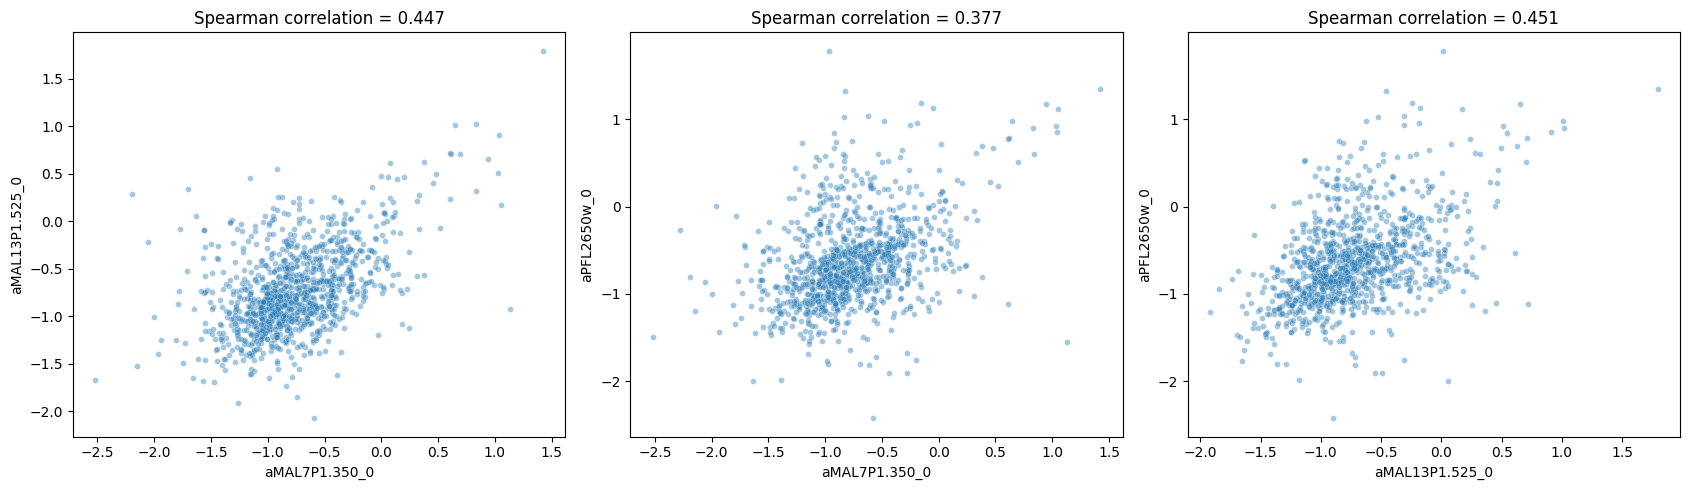

In [102]:
import matplotlib.pyplot as plt
import seaborn as sns

probe_pairs = [
    ("aMAL7P1.350_0", "aMAL13P1.525_0"),
    ("aMAL7P1.350_0", "aPFL2650w_0"),
    ("aMAL13P1.525_0", "aPFL2650w_0")
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (probe_x, probe_y) in zip(axes, probe_pairs):

    sns.scatterplot(
        x=weak_probe_expression[probe_x],
        y=weak_probe_expression[probe_y],
        alpha=0.4,
        s=18,
        ax=ax
    )

    correlation = weak_probe_expression[
        [probe_x, probe_y]
    ].corr(method="spearman").iloc[0, 1]

    ax.set_title(f"Spearman correlation = {correlation:.3f}")
    ax.set_xlabel(probe_x)
    ax.set_ylabel(probe_y)

plt.tight_layout()
plt.show()

In [104]:
# Find DataFrames that may contain probe annotation information
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        if {"ID", "SEQUENCE", "CHROMOSOME", "POSITION"}.issubset(obj.columns):
            print(f"Possible annotation DataFrame: {name}")
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())

Possible annotation DataFrame: weak_probe_annotation
Shape: (3, 7)
Columns: ['ID', 'SEQUENCE', 'CHROMOSOME', 'POSITION', 'ORF', 'ORF_old', 'SPOT_ID']


In [105]:
target_probes = [
    "aMAL13P1.525_0",
    "aMAL7P1.350_0",
    "aPFL2650w_0"
]

probe_sequence_check = weak_probe_annotation[
    weak_probe_annotation["ID"].isin(target_probes)
][["ID", "SEQUENCE", "CHROMOSOME", "POSITION", "ORF", "ORF_old"]].copy()

display(probe_sequence_check)

,ID,SEQUENCE,CHROMOSOME,POSITION,ORF,ORF_old
8784,aMAL13P1.525_0,TGCATGATATTGGAGTGGCACTATCATCTACAGACATTGAACATAC...,Pf3D7_13_v3,2875992.0,PF3D7_1373200,MAL13P1.525
8785,aMAL7P1.350_0,TGCATGATATTGGAGTGGCACTATCATCTACAGACATTGAACATAC...,Pf3D7_13_v3,2875992.0,PF3D7_1373200,MAL13P1.525
8786,aPFL2650w_0,TGCATGATATTGGAGTGGCACTATCATCTACAGACATTGAACATAC...,Pf3D7_13_v3,2875992.0,PF3D7_1373200,MAL13P1.525


In [106]:
sequences = probe_sequence_check.set_index("ID")["SEQUENCE"]

print("Sequence lengths:")
print(sequences.str.len())

print("\nAre all three sequences identical?")
print(sequences.nunique() == 1)

print("\nPairwise sequence comparisons:")
for i in range(len(sequences)):
    for j in range(i + 1, len(sequences)):
        probe_a = sequences.index[i]
        probe_b = sequences.index[j]

        print(
            f"{probe_a} vs {probe_b}:",
            sequences.iloc[i] == sequences.iloc[j]
        )

Sequence lengths:
ID
aMAL13P1.525_0    70
aMAL7P1.350_0     70
aPFL2650w_0       70
Name: SEQUENCE, dtype: int64

Are all three sequences identical?
True

Pairwise sequence comparisons:
aMAL13P1.525_0 vs aMAL7P1.350_0: True
aMAL13P1.525_0 vs aPFL2650w_0: True
aMAL7P1.350_0 vs aPFL2650w_0: True


In [107]:
target_expression = expression_matrix[
    target_probes
].copy()

print("Expression correlation:")
display(target_expression.corr(method="spearman"))

print("\nExpression summary:")
display(target_expression.describe().T)

print("\nFirst 10 samples:")
display(target_expression.head(10))

Expression correlation:


ID_REF,aMAL13P1.525_0,aMAL7P1.350_0,aPFL2650w_0
ID_REF,,,
aMAL13P1.525_0,1.000000,0.447079,0.451408
aMAL7P1.350_0,0.447079,1.000000,0.376994
aPFL2650w_0,0.451408,0.376994,1.000000



Expression summary:


,count,mean,std,min,25%,50%,75%,max
ID_REF,,,,,,,,
aMAL13P1.525_0,1040.0,-0.725908,0.447505,-2.075882,-1.021452,-0.786143,-0.471303,1.794678
aMAL7P1.350_0,1040.0,-0.762805,0.454707,-2.518745,-1.042083,-0.814315,-0.509698,1.423032
aPFL2650w_0,1033.0,-0.623611,0.519379,-2.424563,-0.951745,-0.695562,-0.386022,1.785183



First 10 samples:


ID_REF,aMAL13P1.525_0,aMAL7P1.350_0,aPFL2650w_0
GSM1427365,-0.623060,-0.479017,0.983614
GSM1427366,-1.055832,-0.886058,-0.816712
GSM1427367,0.908529,1.040289,0.850057
GSM1427368,-1.173683,-0.928034,-0.691065
GSM1427369,0.185780,0.006692,0.068543
GSM1427370,-0.109796,-0.201600,0.241100
GSM1427371,-0.507035,-0.860091,-0.766593
GSM1427372,0.495676,0.481441,0.674625
GSM1427373,-0.693182,-0.262468,-0.674454
GSM1427374,-0.834801,-0.833797,-0.550050


In [108]:
# Compare the direction of expression changes across samples

direction_check = pd.DataFrame({
    "probe_1_vs_probe_2": np.sign(
        target_expression.iloc[:, 0]
    ) == np.sign(target_expression.iloc[:, 1]),

    "probe_1_vs_probe_3": np.sign(
        target_expression.iloc[:, 0]
    ) == np.sign(target_expression.iloc[:, 2]),

    "probe_2_vs_probe_3": np.sign(
        target_expression.iloc[:, 1]
    ) == np.sign(target_expression.iloc[:, 2])
})

print("Percentage of samples with matching expression direction:")
display((direction_check.mean() * 100).round(2))

Percentage of samples with matching expression direction:


,0
probe_1_vs_probe_2,92.91
probe_1_vs_probe_3,86.29
probe_2_vs_probe_3,87.25


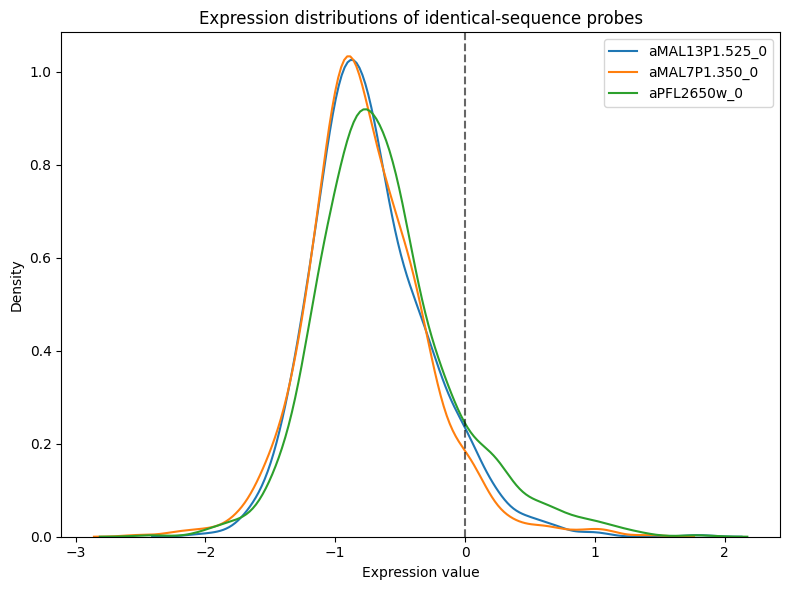

In [109]:
plt.figure(figsize=(8, 6))

for probe in target_probes:
    sns.kdeplot(
        target_expression[probe].dropna(),
        label=probe,
        fill=False
    )

plt.axvline(0, color="black", linestyle="--", alpha=0.6)
plt.xlabel("Expression value")
plt.ylabel("Density")
plt.title("Expression distributions of identical-sequence probes")
plt.legend()
plt.tight_layout()
plt.show()

In [110]:
# Count how many probe IDs share each DNA sequence

sequence_counts = (
    weak_probe_annotation
    .groupby("SEQUENCE")["ID"]
    .nunique()
    .value_counts()
    .sort_index()
)

print("Number of probes sharing each sequence:")
display(sequence_counts)

print("\nSequences shared by multiple probes:")
print(
    (weak_probe_annotation.groupby("SEQUENCE")["ID"].nunique() > 1).sum()
)

Number of probes sharing each sequence:


,count
ID,
3,1



Sequences shared by multiple probes:
1


In [111]:
# Count how many probes share each exact sequence
sequence_counts = (
    weak_probe_annotation
    .groupby("SEQUENCE")["ID"]
    .nunique()
    .value_counts()
    .sort_index()
)

print("Number of probes sharing each sequence:")
display(sequence_counts)

print(
    "Number of sequences shared by multiple probes:",
    (weak_probe_annotation.groupby("SEQUENCE")["ID"].nunique() > 1).sum()
)

Number of probes sharing each sequence:


,count
ID,
3,1


Number of sequences shared by multiple probes: 1


In [112]:
# Inspect available GEO platform objects
print("GEO platforms:", list(gse.gpls.keys()))

# Inspect available files in the working directory
for root, dirs, files in os.walk("data"):
    for file in files[:20]:
        print(os.path.join(root, file))

GEO platforms: ['GPL18893']
data/raw/GSE59097.txt
data/raw/GSE59097_family.soft.gz
data/metadata/GSE59097_sample_metadata.csv


In [113]:
# Access the GPL18893 platform annotation
gpl = gse.gpls["GPL18893"]

print("Platform title:")
print(gpl.metadata.get("title", ["Not available"])[0])

print("\nAnnotation table shape:")
print(gpl.table.shape)

print("\nAnnotation columns:")
print(gpl.table.columns.tolist())

print("\nFirst 5 annotation records:")
display(gpl.table.head())

Platform title:
ZB/SBS-NTU Plasmodium falciparum 3D7 11.4K v2

Annotation table shape:
(11372, 7)

Annotation columns:
['ID', 'SEQUENCE', 'CHROMOSOME', 'POSITION', 'ORF', 'ORF_old', 'SPOT_ID']

First 5 annotation records:


,ID,SEQUENCE,CHROMOSOME,POSITION,ORF,ORF_old,SPOT_ID
0,aPFA0005w_0,AACCTAAAGAAAAAACCTGTGGAAAAACAAAGACATACGATCCTAA...,Pf3D7_01_v3,31035.0,PF3D7_0100100,PFA0005w,NaN
1,aPFA0005w_1,TATATGAATCAACCGACTATGACGATGAAGAAAAAGATCCACAAGA...,Pf3D7_01_v3,32538.0,PF3D7_0100100,PFA0005w,NaN
2,aPFA0005w_2,TATGAAGAACAAAAAACAAAATGCCAAAAGGAAAGTAAGAGTGCTA...,Pf3D7_01_v3,33368.0,PF3D7_0100100,PFA0005w,NaN
3,aPFA0005w_3,AACATTTGTCCAACAAAACAACCACAACCAGAGAAAGAAGACGGTT...,Pf3D7_01_v3,34424.0,PF3D7_0100100,PFA0005w,NaN
4,aPFA0010c_0,GCAGGGATTGAAGGATTAAGAGATTTTTCTGGTCTGGGTAAATTAA...,Pf3D7_01_v3,39350.0,PF3D7_0100200,PFA0010c,NaN


In [114]:
# Copy the complete platform annotation
full_annotation = gpl.table.copy()

# Remove records without probe IDs or sequences
full_annotation = full_annotation.dropna(
    subset=["ID", "SEQUENCE"]
).copy()

# Count unique probe IDs sharing each sequence
sequence_groups = (
    full_annotation
    .groupby("SEQUENCE")["ID"]
    .nunique()
)

# Summarise sequence duplication
print("Total annotated probes:", full_annotation["ID"].nunique())
print("Unique sequences:", sequence_groups.size)
print(
    "Sequences shared by multiple probes:",
    (sequence_groups > 1).sum()
)
print(
    "Probes belonging to duplicated-sequence groups:",
    sequence_groups[sequence_groups > 1].sum()
)

print("\nDistribution of probes per sequence:")
display(sequence_groups.value_counts().sort_index())

Total annotated probes: 11372
Unique sequences: 11239
Sequences shared by multiple probes: 108
Probes belonging to duplicated-sequence groups: 241

Distribution of probes per sequence:


,count
ID,
1,11131
2,96
3,8
4,1
7,3


In [115]:
# Identify probes present in the expression matrix
expression_probe_ids = set(expression_matrix.columns)

# Keep annotation records represented in the expression matrix
matched_annotation = full_annotation[
    full_annotation["ID"].isin(expression_probe_ids)
].copy()

# Count probes sharing each sequence among expressed probes
expressed_sequence_counts = (
    matched_annotation
    .groupby("SEQUENCE")["ID"]
    .nunique()
)

duplicated_expressed = expressed_sequence_counts[
    expressed_sequence_counts > 1
]

print("Expression matrix probes:", len(expression_probe_ids))
print("Annotated probes found in expression matrix:",
      matched_annotation["ID"].nunique())
print("Expression probes without annotation:",
      len(expression_probe_ids - set(full_annotation["ID"])))

print("\nDuplicated sequences represented in expression matrix:",
      len(duplicated_expressed))

print("Probes in duplicated-sequence groups:",
      duplicated_expressed.sum())

print("\nDistribution of duplicated groups:")
display(duplicated_expressed.value_counts().sort_index())

Expression matrix probes: 11005
Annotated probes found in expression matrix: 11005
Expression probes without annotation: 0

Duplicated sequences represented in expression matrix: 87
Probes in duplicated-sequence groups: 199

Distribution of duplicated groups:


,count
ID,
2,75
3,8
4,1
7,3


In [116]:
# Identify all probes belonging to duplicated-sequence groups
duplicated_sequence_ids = duplicated_expressed.index

duplicated_probe_details = matched_annotation[
    matched_annotation["SEQUENCE"].isin(duplicated_sequence_ids)
].copy()

# Summarise each duplicated sequence
duplicate_group_summary = (
    duplicated_probe_details
    .groupby("SEQUENCE")
    .agg(
        number_of_probes=("ID", "nunique"),
        probe_ids=("ID", lambda x: list(x)),
        chromosomes=("CHROMOSOME", lambda x: list(pd.unique(x))),
        positions=("POSITION", lambda x: list(pd.unique(x))),
        genes=("ORF", lambda x: list(pd.unique(x))),
        old_gene_ids=("ORF_old", lambda x: list(pd.unique(x)))
    )
    .reset_index(drop=True)
    .sort_values("number_of_probes", ascending=False)
)

display(duplicate_group_summary.head(15))

,number_of_probes,probe_ids,chromosomes,positions,genes,old_gene_ids
18,7,"[aMAL7P1.3_0, aPF10_0392_0, aPF11_0023_0, aPFA...",[Pf3D7_11_v3],[80342.0],[PF3D7_1101500],[PF11_0023]
57,7,"[aPF10_0388_0, aPF11_0026_0, aPFA0070c_0, aPFB...",[Pf3D7_11_v3],[87673.0],[PF3D7_1101800],[PF11_0026]
27,7,"[aMAL7P1.4_0, aPF10_0391_0, aPF11_0024_0, aPFA...",[Pf3D7_11_v3],[83298.0],[PF3D7_1101600],[PF11_0024]
31,4,"[aMAL8P1.209_0, aPF11_0522_0, aPFA0075w_1, aPF...",[Pf3D7_12_v3],[1702630.0],[PF3D7_1240300],[PFL1950w]
28,3,"[bHB3vsa_13, bHB3vsa_25, bHB3vsa_36]",[nan],[nan],[nan],[nan]
16,3,"[bHB3vsa_149, bHB3vsa_76, bHB3vsa_80]",[nan],[nan],[nan],[nan]
73,3,"[ac14rRNA.1-5s_0, ac14rRNA.2-5s_0, ac14rRNA.3-...",[Pf3D7_14_v3],[779381.0],[PF3D7_1418500],[MAL14_5S_1]
48,3,"[bHB3vsa_151, bHB3vsa_77, bHB3vsa_81]",[nan],[nan],[nan],[nan]
68,3,"[acoI_mit_1, acoxI_mit_0, acoxIII_mit_1]",[Pf3D7_14_v3],[nan],[nan],[nan]
75,3,"[aMAL13P1.525_0, aMAL7P1.350_0, aPFL2650w_0]",[Pf3D7_13_v3],[2875992.0],[PF3D7_1373200],[MAL13P1.525]


In [117]:
def classify_mapping(group):
    chromosome_count = group["CHROMOSOME"].nunique()
    position_count = group["POSITION"].nunique()
    gene_count = group["ORF"].nunique()

    has_missing = group[
        ["CHROMOSOME", "POSITION", "ORF"]
    ].isna().any().any()

    if chromosome_count == 0 or position_count == 0 or gene_count == 0:
        return "Missing genomic annotation"

    if chromosome_count == 1 and position_count == 1 and gene_count == 1:
        if has_missing:
            return "Partially missing annotation"
        return "Consistent genomic mapping"

    return "Conflicting genomic mapping"


mapping_classification = (
    duplicated_probe_details
    .groupby("SEQUENCE")
    .apply(classify_mapping, include_groups=False)
    .value_counts()
)

print("Classification of duplicated-sequence groups:")
display(mapping_classification)

Classification of duplicated-sequence groups:


,count
Consistent genomic mapping,44
Missing genomic annotation,41
Partially missing annotation,2


In [118]:
# Select duplicated sequences with missing genomic annotations
missing_annotation_groups = []

for sequence, group in duplicated_probe_details.groupby("SEQUENCE"):

    if group[["CHROMOSOME", "POSITION", "ORF"]].isna().all().any():
        if group["CHROMOSOME"].isna().all():
            missing_annotation_groups.append(sequence)

missing_annotation_details = duplicated_probe_details[
    duplicated_probe_details["SEQUENCE"].isin(
        missing_annotation_groups
    )
].copy()

print("Missing-annotation sequence groups:",
      len(missing_annotation_groups))

print("\nProbe identifiers and annotations:")
display(
    missing_annotation_details[
        ["ID", "CHROMOSOME", "POSITION", "ORF", "ORF_old"]
    ].sort_values("ID").head(30)
)

Missing-annotation sequence groups: 37

Probe identifiers and annotations:


,ID,CHROMOSOME,POSITION,ORF,ORF_old
10444,bDd2rif_23,NaN,NaN,NaN,NaN
10494,bDd2rif_69,NaN,NaN,NaN,NaN
10521,bDd2ste_10,NaN,NaN,NaN,NaN
10529,bDd2ste_18,NaN,NaN,NaN,NaN
10532,bDd2ste_20,NaN,NaN,NaN,NaN
10543,bDd2ste_5,NaN,NaN,NaN,NaN
10546,bDd2ste_8,NaN,NaN,NaN,NaN
10558,bDd2var_108,NaN,NaN,NaN,NaN
10576,bDd2var_124,NaN,NaN,NaN,NaN
10577,bDd2var_125,NaN,NaN,NaN,NaN


In [120]:
print("Columns:")
print(duplicate_group_summary.columns.tolist())

print("\nTable shape:")
print(duplicate_group_summary.shape)

print("\nFirst 10 rows:")
display(duplicate_group_summary.head(10))

Columns:
['number_of_probes', 'probe_ids', 'chromosomes', 'positions', 'genes', 'old_gene_ids']

Table shape:
(87, 6)

First 10 rows:


,number_of_probes,probe_ids,chromosomes,positions,genes,old_gene_ids
18,7,"[aMAL7P1.3_0, aPF10_0392_0, aPF11_0023_0, aPFA...",[Pf3D7_11_v3],[80342.0],[PF3D7_1101500],[PF11_0023]
57,7,"[aPF10_0388_0, aPF11_0026_0, aPFA0070c_0, aPFB...",[Pf3D7_11_v3],[87673.0],[PF3D7_1101800],[PF11_0026]
27,7,"[aMAL7P1.4_0, aPF10_0391_0, aPF11_0024_0, aPFA...",[Pf3D7_11_v3],[83298.0],[PF3D7_1101600],[PF11_0024]
31,4,"[aMAL8P1.209_0, aPF11_0522_0, aPFA0075w_1, aPF...",[Pf3D7_12_v3],[1702630.0],[PF3D7_1240300],[PFL1950w]
28,3,"[bHB3vsa_13, bHB3vsa_25, bHB3vsa_36]",[nan],[nan],[nan],[nan]
16,3,"[bHB3vsa_149, bHB3vsa_76, bHB3vsa_80]",[nan],[nan],[nan],[nan]
73,3,"[ac14rRNA.1-5s_0, ac14rRNA.2-5s_0, ac14rRNA.3-...",[Pf3D7_14_v3],[779381.0],[PF3D7_1418500],[MAL14_5S_1]
48,3,"[bHB3vsa_151, bHB3vsa_77, bHB3vsa_81]",[nan],[nan],[nan],[nan]
68,3,"[acoI_mit_1, acoxI_mit_0, acoxIII_mit_1]",[Pf3D7_14_v3],[nan],[nan],[nan]
75,3,"[aMAL13P1.525_0, aMAL7P1.350_0, aPFL2650w_0]",[Pf3D7_13_v3],[2875992.0],[PF3D7_1373200],[MAL13P1.525]


In [122]:
def is_missing_annotation(value):
    if value is None:
        return True

    if isinstance(value, (list, tuple, np.ndarray)):
        return all(
            pd.isna(item) or str(item).strip().lower() in ["nan", "none", ""]
            for item in value
        )

    return pd.isna(value) or str(value).strip().lower() in ["nan", "none", ""]


def classify_annotation(row):
    chromosome_missing = is_missing_annotation(row["chromosomes"])
    position_missing = is_missing_annotation(row["positions"])
    gene_missing = is_missing_annotation(row["genes"])

    if chromosome_missing and position_missing and gene_missing:
        return "Missing genomic annotation"

    if chromosome_missing or position_missing or gene_missing:
        return "Partially missing annotation"

    return "Consistent genomic mapping"


duplicate_group_summary["annotation_class"] = (
    duplicate_group_summary.apply(classify_annotation, axis=1)
)

print("Total duplicated groups:", len(duplicate_group_summary))
print("\nClassification counts:")
display(duplicate_group_summary["annotation_class"].value_counts())

Total duplicated groups: 87

Classification counts:


,count
annotation_class,
Consistent genomic mapping,46
Missing genomic annotation,37
Partially missing annotation,4


In [123]:
# Check missing values in the expression matrix
print("Expression matrix shape:", expression_matrix.shape)

missing_values = expression_matrix.isna().sum().sum()
total_values = expression_matrix.size

print("Total expression values:", total_values)
print("Missing expression values:", missing_values)
print("Missing percentage:", round(missing_values / total_values * 100, 4), "%")

# Check probes with constant expression
probe_variance = expression_matrix.var(axis=1)

constant_probes = (probe_variance == 0).sum()

print("\nTotal probes:", len(probe_variance))
print("Constant-expression probes:", constant_probes)

Expression matrix shape: (1043, 11005)
Total expression values: 11478215
Missing expression values: 488513
Missing percentage: 4.256 %

Total probes: 1043
Constant-expression probes: 0


In [124]:
# Missing values per sample
missing_per_sample = expression_matrix.isna().sum(axis=1)

# Missing values per probe
missing_per_probe = expression_matrix.isna().sum(axis=0)

print("Missing values per sample:")
print(missing_per_sample.describe())

print("\nMissing values per probe:")
print(missing_per_probe.describe())

# Correct probe-level variance across samples
probe_variance = expression_matrix.var(axis=0)

print("\nProbe variance across samples:")
print(probe_variance.describe())

print("\nConstant-expression probes:")
print((probe_variance == 0).sum())

Missing values per sample:
count    1043.000000
mean      468.372963
std       361.747051
min        10.000000
25%       214.000000
50%       381.000000
75%       610.500000
max      2700.000000
dtype: float64

Missing values per probe:
count    11005.000000
mean        44.390095
std         69.790234
min          0.000000
25%          3.000000
50%          9.000000
75%         51.000000
max        377.000000
dtype: float64

Probe variance across samples:
count    11005.000000
mean         0.347098
std          0.263683
min          0.030767
25%          0.180635
50%          0.267260
75%          0.418602
max          3.427489
dtype: float64

Constant-expression probes:
0


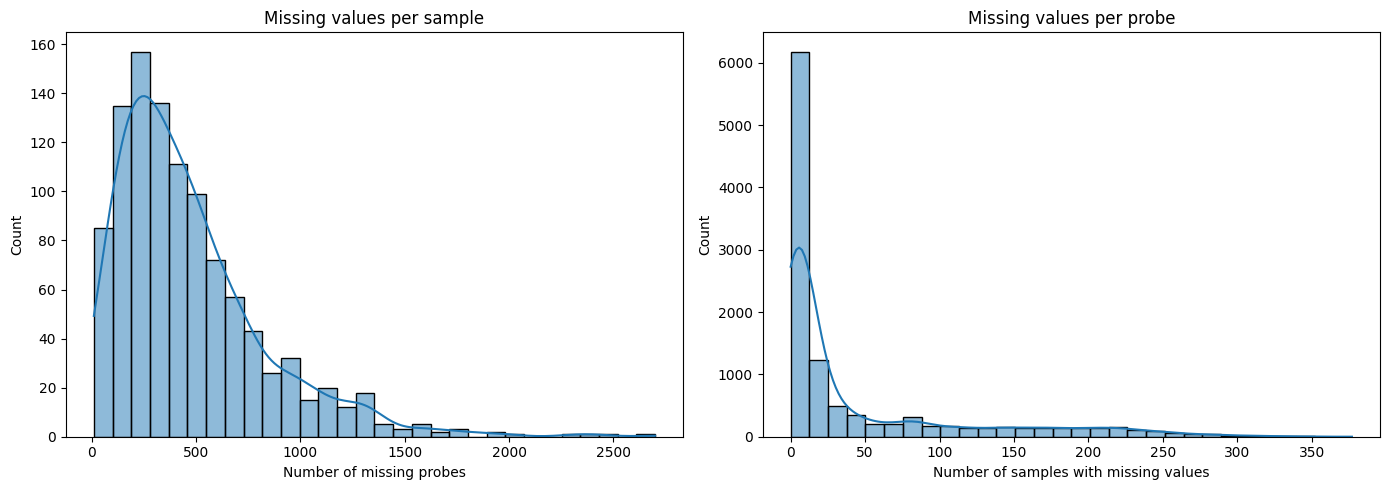

In [125]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Missing values per sample
sns.histplot(
    missing_per_sample,
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Missing values per sample")
axes[0].set_xlabel("Number of missing probes")

# Missing values per probe
sns.histplot(
    missing_per_probe,
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Missing values per probe")
axes[1].set_xlabel("Number of samples with missing values")

plt.tight_layout()
plt.show()

In [126]:
# Calculate missing values for each sample
sample_missingness = expression_matrix.isna().sum(axis=1)

# Create a summary table
sample_missingness_df = pd.DataFrame({
    "GSM_ID": expression_matrix.index,
    "missing_values": sample_missingness.values,
    "missing_percentage": (
        sample_missingness.values / expression_matrix.shape[1]
    ) * 100
})

# Show the 15 samples with the most missing values
sample_missingness_df = sample_missingness_df.sort_values(
    "missing_percentage",
    ascending=False
)

display(sample_missingness_df.head(15))

,GSM_ID,missing_values,missing_percentage
706,GSM1428071,2700,24.534303
764,GSM1428129,2436,22.135393
6,GSM1427371,2365,21.490232
286,GSM1427651,2303,20.926851
50,GSM1427415,2001,18.182644
1038,GSM1428403,1949,17.710132
811,GSM1428176,1893,17.201272
154,GSM1427519,1790,16.265334
917,GSM1428282,1784,16.210813
89,GSM1427454,1773,16.110859


In [127]:
# Identify the sample ID column in metadata
id_col = "gsm_id" if "gsm_id" in metadata.columns else "GSM_ID"

# Select metadata fields that are available
wanted_columns = [
    id_col,
    "geographic_origin",
    "clearance_half_life",
    "stage",
    "culture"
]

available_columns = [
    col for col in wanted_columns
    if col in metadata.columns
]

# Prepare metadata for merging
metadata_check = metadata[available_columns].copy()
metadata_check = metadata_check.drop_duplicates(subset=id_col)
metadata_check = metadata_check.set_index(id_col)

# Combine missingness information with metadata
sample_quality = sample_missingness_df.set_index("GSM_ID").join(
    metadata_check,
    how="left"
)

# Display the 15 samples with the highest missingness
display(sample_quality.head(15))

,missing_values,missing_percentage,geographic_origin,clearance_half_life,stage,culture
GSM_ID,,,,,,
GSM1428071,2700,24.534303,"Shwe Kyin, Myanmar",3.109,blood,in vivo
GSM1428129,2436,22.135393,"Mae Sot, Thailand",4.912,blood,in vivo
GSM1427371,2365,21.490232,"Ramu, Bangladesh",2.445,blood,in vivo
GSM1427651,2303,20.926851,"Preah Vihear, Cambodia",3.379,blood,in vivo
GSM1427415,2001,18.182644,"Ramu, Bangladesh",2.07,blood,in vivo
GSM1428403,1949,17.710132,"Binh Phuoc, Vietnam",1.146,blood,in vivo
GSM1428176,1893,17.201272,"Mae Sot, Thailand",6.034,blood,in vivo
GSM1427519,1790,16.265334,"Kinshasa, DRCongo",1.321,blood,in vivo
GSM1428282,1784,16.210813,"Ranong, Thailand",5.066,blood,in vivo


In [128]:
# Summarise missingness by geographic origin
missingness_by_location = (
    sample_quality
    .groupby("geographic_origin")
    .agg(
        sample_count=("missing_percentage", "count"),
        mean_missing_percentage=("missing_percentage", "mean"),
        median_missing_percentage=("missing_percentage", "median"),
        max_missing_percentage=("missing_percentage", "max")
    )
    .sort_values("mean_missing_percentage", ascending=False)
)

display(missingness_by_location.round(2))

,sample_count,mean_missing_percentage,median_missing_percentage,max_missing_percentage
geographic_origin,,,,
"Sisakhet, Thailand",27,5.30,4.53,11.79
"Ramu, Bangladesh",53,5.22,4.32,21.49
"Ranong, Thailand",21,5.08,4.09,16.21
"Khun Han, Thailand",9,4.83,4.59,11.99
"Binh Phuoc, Vietnam",113,4.67,3.92,17.71
"Rattanakiri, Cambodia",106,4.48,3.99,12.44
"Mae Sot, Thailand",121,4.35,3.53,22.14
"Preah Vihear, Cambodia",116,4.22,3.38,20.93
"Attapeu, Laos",87,4.17,3.33,14.44


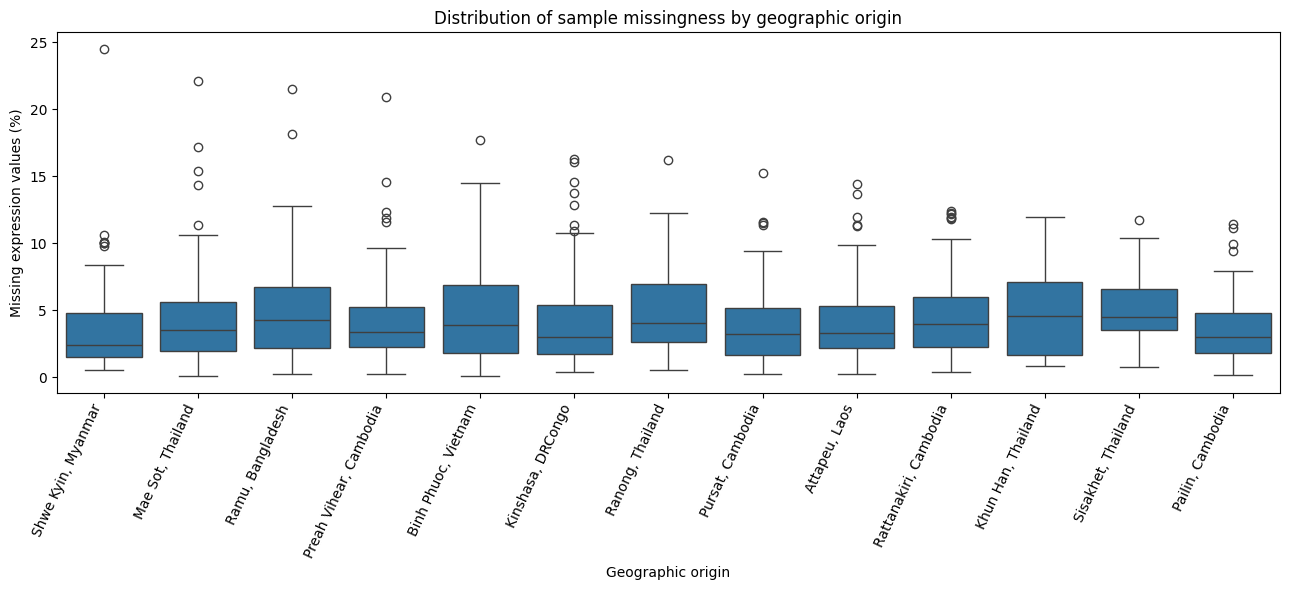

In [129]:
plt.figure(figsize=(13, 6))

sns.boxplot(
    data=sample_quality.reset_index(),
    x="geographic_origin",
    y="missing_percentage"
)

plt.xticks(rotation=65, ha="right")
plt.xlabel("Geographic origin")
plt.ylabel("Missing expression values (%)")
plt.title("Distribution of sample missingness by geographic origin")
plt.tight_layout()
plt.show()


## Preliminary Dataset Assessment: GSE59097

**Study design:** In vivo field-isolate expression profiling.

**Sample size:** 1,043 samples.

**Expression matrix:** 1,043 samples × 11,005 probes.

**Platform:** GPL18893.

**Resistance phenotype:** Parasite clearance half-life available for 1,025 samples.

**Data quality:** Overall expression missingness of 4.256%. No constant-expression probes detected.

**Annotation:** Platform annotation available. Duplicate probe sequences and missing genomic annotations require further consideration if this dataset is selected.

**Developmental-stage information:** Current sample metadata contains a broad "blood" label. Availability of finer developmental-stage information remains to be investigated.

**Preliminary decision:** Retain as a potential candidate. Final suitability depends on developmental-stage information, phenotype compatibility, and cross-dataset comparability.

